# Introduction to Graph Neural Nets with JAX/jraph

*Lisa Wang, DeepMind (wanglisa@deepmind.com), Nikola Jovanović, ETH Zurich (nikola.jovanovic@inf.ethz.ch)*

**Colab Runtime:**

If possible, please use a GPU hardware accelerator to run this colab. You can choose that under *Runtime > Change Runtime Type*.

**Prerequisites:**
* Some familiarity with [JAX](https://github.com/google/jax), you can refer to this [colab](https://colab.sandbox.google.com/github/google/jax/blob/master/docs/jax-101/01-jax-basics.ipynb) for an introduction to JAX.
* Neural network basics
* Graph theory basics (MIT Open Courseware [slides](https://ocw.mit.edu/courses/civil-and-environmental-engineering/1-022-introduction-to-network-models-fall-2018/lecture-notes/MIT1_022F18_lec2.pdf) by Amir Ajorlou)


We recommend watching the [Theoretical Foundations of Graph Neural Networks Lecture](https://www.youtube.com/watch?v=uF53xsT7mjc&) by Petar Veličković before working through this colab. The talk provides a theoretical introduction to Graph Neural Networks (GNNs), historical context and motivating examples.


**Outline:**
* [Fundamental Graph Concepts](#scrollTo=gsKA-syx_LUi)
* [Graph Prediction Tasks](#scrollTo=spQGRxhPN8Eo)
* [Intro to the jraph Library](#scrollTo=3C5YI9M0vwvb)
* [Graph Convolutional Network (GCN) Layer](#scrollTo=NZRMF2d-h2pd)
* [Build GCN Model with Multiple Layers](#scrollTo=lha8rbQ78l3S)
* [Node Classification with GCN on Karate Club Dataset](#scrollTo=Z5t7kw7SE_h4)
* [Graph Attention (GAT) Layer](#scrollTo=yg8g96NdBCK6)
* [Train GAT Model on Karate Club Dataset](#scrollTo=anfVGJwBe27v)
* [Graph Classification on MUTAG (Molecules)](#scrollTo=n5TxaTGzBkBa)
* [Link Prediction on CORA (Citation Network)](#scrollTo=OwVE88dTRC6V)
* [Bonus: Intro to Graph Adversarial Attacks](#scrollTo=35kbP8GZRFEm)


**Additional Resources:**

* Battaglia et al. (2018): [Relational inductive biases, deep learning, and graph networks](https://arxiv.org/pdf/1806.01261)

---

Some sections in this colab build on the [GraphNets Tutorial colab in pytorch](https://github.com/eemlcommunity/PracticalSessions2021/blob/main/graphnets/graphnets_tutorial.ipynb) by Nikola Jovanović.

We would like to thank Razvan Pascanu and Petar Veličković for their valuable input and feedback.

---
*Copyright 2022 by the Authors.*

*Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at https://www.apache.org/licenses/LICENSE-2.0*

*Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.*

## Setup: Install and Import libraries

In [1]:
!pip install jraph flax dm-haiku matplotlib networkx scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.3/374.3 kB 9.5 MB/s eta 0:00:00:00:01


In [1]:
# Imports
%matplotlib inline
import functools
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.tree_util as tree
import jraph
import flax
import haiku as hk
import optax
import pickle
import numpy as onp
import networkx as nx
from typing import Any, Callable, Dict, List, Optional, Tuple
from sklearn.metrics import roc_auc_score
import time

## Fundamental Graph Concepts
A graph consists of a set of nodes and a set of edges, where edges form connections between nodes.

More formally, a graph is defined as $ \mathcal{G} = (\mathcal{V}, \mathcal{E})$ where $\mathcal{V}$ is the set of vertices / nodes, and $\mathcal{E}$ is the set of edges.

In an **undirected** graph, each edge is an unordered pair of two nodes $ \in \mathcal{V}$. E.g. a friend network can be represented as an undirected graph, assuming that the relationship "*A is friends with B*" implies "*B is friends with A*".

In a **directed** graph, each edge is an ordered pair of nodes $ \in \mathcal{V}$. E.g. a citation network would be best represented with a directed graph, since the relationship "*A cites B*" does not imply "*B cites A*".

The **degree** of a node is defined as the number of edges incident on it, i.e. the sum of incoming and outgoing edges for that node.

The **in-degree** is the sum of incoming edges only, and the **out-degree** is the sum of outgoing edges only.

There are several ways to represent $\mathcal{E}$:
1. As a **list of edges**: a list of pairs $(u,v)$, where $(u,v)$ means that there is an edge going from node $u$ to node $v$.
2. As an **adjacency matrix**: a binary square matrix $A$ of size $|\mathcal{V}| \times |\mathcal{V}|$, where $A_{u,v}=1$ iff there is a connection between nodes $u$ and $v$.
3. As an **adjacency list**: An array of $|\mathcal{V}|$ unordered lists, where the $i$th list corresponds to the $i$th node, and contains all the nodes directly connected to node $i$.


Example: Below is a directed graph with four nodes and five edges.

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/toy_graph.png" width="400px">

The arrows on the edges indicate the direction of each edge, e.g. there is an edge going from node 0 to node 1. Between node 0 and node 3, there are two edges: one going from node 0 to node 3 and one from node 3 to node 0.

Node 0 has out-degree of 2, since it has two outgoing edges, and an in-degree of 2, since it has two incoming edges.

The list of edges is:
$$[(0, 1), (0, 3), (1, 2), (2, 0), (3, 0)]$$

As adjacency matrix:

$$\begin{array}{l|llll}
 source \setminus dest    & n_0 & n_1 & n_2 & n_3 \\ \hline
n_0 & 0    & 1    & 0    & 1    \\
n_1 & 0    & 0    & 1    & 0    \\
n_2 & 1    & 0    & 0    & 0    \\
n_3 & 1    & 0    & 0    & 0
\end{array}$$

As adjacency list:

$$[\{1, 3\}, \{2\}, \{0\}, \{0\}]$$



## Graph Prediction Tasks
What are the kinds of problems we want to solve on graphs?


The tasks fall into roughly three categories:

1. **Node Classification**: E.g. what is the topic of a paper given a citation network of papers?
2. **Link Prediction / Edge Classification**: E.g. are two people in a social network friends?
3. **Graph Classification**: E.g. is this protein molecule (represented as a graph) likely going to be effective?

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/graph_tasks.png" width="700px">

*The three main graph learning tasks. Image source: Petar Veličković.*

Which examples of graph prediction tasks come to your mind? Which task types do they correspond to?

We will create and train models on all three task types in this tutorial.


# Intro to the jraph Library

In the following sections, we will learn how to represent graphs and build GNNs in Python. We will use
[jraph](https://github.com/deepmind/jraph), a lightweight library for working with GNNs in [JAX](https://github.com/google/jax).

## Representing a graph in jraph

In jraph, a graph is represented with a `GraphsTuple` object. In addition to defining the graph structure of nodes and edges, you can also store node features, edge features and global graph features in a `GraphsTuple`.

In the `GraphsTuple`, edges are represented in two aligned arrays of node indices: senders (source nodes) and receivers (destinaton nodes).
Each index corresponds to one edge, e.g. edge `i` goes from `senders[i]` to `receivers[i]`.

You can even store multiple graphs in one `GraphsTuple` object.

We will start with creating a simple directed graph with 4 nodes and 5 edges. We will also add toy features to the nodes, using `2*node_index` as the feature.

We will later use this toy graph in the GCN demo.



In [2]:
def build_toy_graph() -> jraph.GraphsTuple:
  """Define a four node graph, each node has a scalar as its feature."""

  # Nodes are defined implicitly by their features.
  # We will add four nodes, each with a feature, e.g.
  # node 0 has feature [0.],
  # node 1 has featre [2.] etc.
  # len(node_features) is the number of nodes.
  node_features = jnp.array([[0.], [2.], [4.], [6.]])

  # We will now specify 5 directed edges connecting the nodes we defined above.
  # We define this with `senders` (source node indices) and `receivers`
  # (destination node indices).
  # For example, to add an edge from node 0 to node 1, we append 0 to senders,
  # and 1 to receivers.
  # We can do the same for all 5 edges:
  # 0 -> 1
  # 1 -> 2
  # 2 -> 0
  # 3 -> 0
  # 0 -> 3
  senders = jnp.array([0, 1, 2, 3, 0])
  receivers = jnp.array([1, 2, 0, 0, 3])

  # You can optionally add edge attributes to the 5 edges.
  edges = jnp.array([[5.], [6.], [7.], [8.], [8.]])

  # We then save the number of nodes and the number of edges.
  # This information is used to make running GNNs over multiple graphs
  # in a GraphsTuple possible.
  n_node = jnp.array([4])
  n_edge = jnp.array([5])

  # Optionally you can add `global` information, such as a graph label.
  global_context = jnp.array([[1]]) # Same feature dims as nodes and edges.
  graph = jraph.GraphsTuple(
      nodes=node_features,
      edges=edges,
      senders=senders,
      receivers=receivers,
      n_node=n_node,
      n_edge=n_edge,
      globals=global_context
      )
  return graph

In [3]:
graph = build_toy_graph()

## Inspecting the GraphsTuple


In [4]:
# Number of nodes
# Note that `n_node` returns an array. The length of `n_node` corresponds to
# the number of graphs stored in one `GraphsTuple`.
# In this case, we only have one graph, so n_node has length 1.
graph.n_node

Array([4], dtype=int32)

In [5]:
# Number of edges
graph.n_edge

Array([5], dtype=int32)

In [6]:
# Node features
graph.nodes

Array([[0.],
       [2.],
       [4.],
       [6.]], dtype=float32)

In [7]:
# Edge features
graph.edges

Array([[5.],
       [6.],
       [7.],
       [8.],
       [8.]], dtype=float32)

In [8]:
# Edges
graph.senders

Array([0, 1, 2, 3, 0], dtype=int32)

In [9]:
graph.receivers

Array([1, 2, 0, 0, 3], dtype=int32)

In [10]:
# Graph-level features
graph.globals

Array([[1]], dtype=int32)

## Visualizing the Graph
To visualize the graph structure of the graph we created above, we will use the [`networkx`](networkx.org) library because it already has functions for drawing graphs.

We first convert the `jraph.GraphsTuple` to a `networkx.DiGraph`.

In [11]:
def convert_jraph_to_networkx_graph(jraph_graph: jraph.GraphsTuple) -> nx.Graph:
  nodes, edges, receivers, senders, _, _, _ = jraph_graph
  nx_graph = nx.DiGraph()
  if nodes is None:
    for n in range(jraph_graph.n_node[0]):
      nx_graph.add_node(n)
  else:
    for n in range(jraph_graph.n_node[0]):
      nx_graph.add_node(n, node_feature=nodes[n])
  if edges is None:
    for e in range(jraph_graph.n_edge[0]):
      nx_graph.add_edge(int(senders[e]), int(receivers[e]))
  else:
    for e in range(jraph_graph.n_edge[0]):
      nx_graph.add_edge(
          int(senders[e]), int(receivers[e]), edge_feature=edges[e])
  return nx_graph


def draw_jraph_graph_structure(jraph_graph: jraph.GraphsTuple) -> None:
  nx_graph = convert_jraph_to_networkx_graph(jraph_graph)
  pos = nx.spring_layout(nx_graph)
  nx.draw(
      nx_graph, pos=pos, with_labels=True, node_size=500, font_color='yellow')

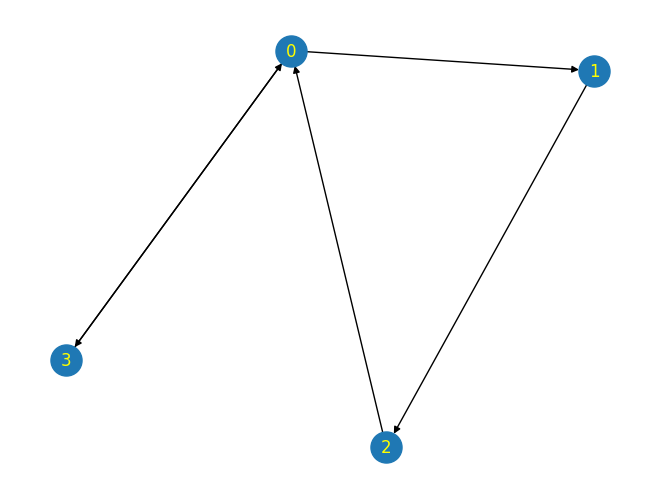

In [12]:
draw_jraph_graph_structure(graph)

# Graph Convolutional Network (GCN) Layer
Now let's implement our first graph network!

The graph convolutional network, introduced by by Kipf et al. (2017) in https://arxiv.org/abs/1609.02907, is one of the basic graph network architectures. We will build its core building block, the graph convolutional layer.

In a convolutional neural network (CNN), a convolutional filter (e.g. 3x3) is applied repeatedly to different parts of a larger input (e.g. 64x64) by striding across the input.

In a GCN, a convolution filter is applied to the neighbourhoods around a node in a graph.

However, there are also some differences to point out:
In contrast to the CNN filter, the neighbourhoods in a GCN can be of different sizes, and there is no ordering of inputs. To see that, note that the CNN filter performs a weighted sum aggregation over the inputs with learnable weights, where each filter input has its own weight. In the GCN, the same weight is applied to all neighbours and the aggregation function is not learned. In other words, in a GCN, each neighbor contributes equally. This is why the CNN filter is not order-invariant, but the GCN filter is.


<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/cnn_vs_gnn.png" width="400px">

Comparison of CNN and GCN filters.
Image source: https://arxiv.org/pdf/1901.00596.pdf

More specifically, the GCN layer performs two steps:

1. _Compute messages / update node features_: Create a feature vector $\vec{h}_n$ for each node $n$ (e.g. with an MLP). This is going to be the message that this node will pass to neighboring nodes.
2. _Message-passing / aggregate node features_: For each node, calculate a new feature vector $\vec{h}'_n$ based on the messages (features) from the nodes in its neighborhood. In a directed graph, only nodes from incoming edges are counted as neighbors. The image below shows this aggregation step. There are multiple options for aggregation in a GCN, e.g. taking the mean, the sum, the min or max. (Later in this tutorial, we will also see how we can make the aggregation function dependent on the node features by adding an attention mechanism in the Graph Attention Network.)

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/graph_conv.png" width="500px">

*\"A generic overview of a graph convolution operation, highlighting the relevant information for deriving the next-level features for every node in the graph.\"* Image source: Petar Veličković (https://github.com/PetarV-/TikZ)


#### Simple GCN Layer

In [13]:
def apply_simplified_gcn(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  # Unpack GraphsTuple
  nodes, _, receivers, senders, _, _, _ = graph

  # 1. Update node features
  # For simplicity, we will first use an identify function here, and replace it
  # with a trainable MLP block later.
  update_node_fn = lambda nodes: nodes
  nodes = update_node_fn(nodes)

  # 2. Aggregate node features over nodes in neighborhood
  # Equivalent to jnp.sum(n_node), but jittable
  total_num_nodes = tree.tree_leaves(nodes)[0].shape[0]
  aggregate_nodes_fn = jax.ops.segment_sum

  # Compute new node features by aggregating messages from neighboring nodes
  nodes = tree.tree_map(lambda x: aggregate_nodes_fn(x[senders], receivers,
                                        total_num_nodes), nodes)
  out_graph = graph._replace(nodes=nodes)
  return out_graph

We can now run the graph convolution on our toy graph from before.

In [14]:
graph = build_toy_graph()

Here is the visualized graph.

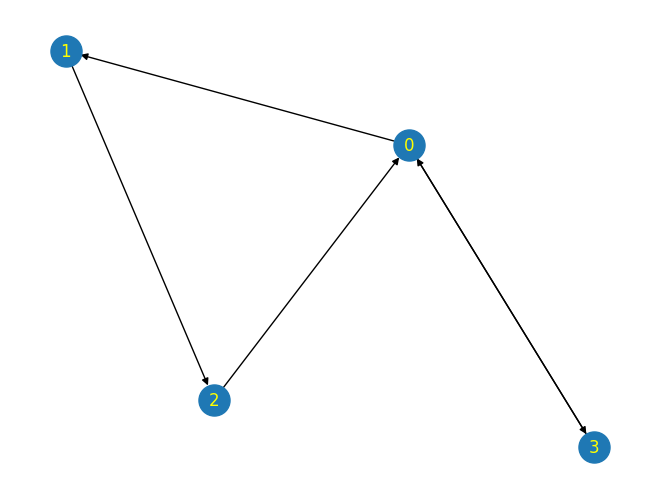

In [15]:
draw_jraph_graph_structure(graph)

In [16]:
out_graph = apply_simplified_gcn(graph)

Since we used the identity function for updating nodes and sum aggregation, we can verify the results pretty easily. As a reminder, in this toy graph, the node features are the same as the node index.

Node 0: sum of features from node 2 and node 3 $\rightarrow$ 10.

Node 1: sum of features from node 0 $\rightarrow$ 0.

Node 2: sum of features from node 1 $\rightarrow$ 2.

Node 3: sum of features from node 0 $\rightarrow$ 0.

In [17]:
out_graph.nodes

Array([[10.],
       [ 0.],
       [ 2.],
       [ 0.]], dtype=float32)

#### Add Trainable Parameters to GCN layer
So far our graph convolution operation doesn't have any learnable parameters.
Let's add an MLP block to the update function to make it trainable.

In [18]:
class MLP(hk.Module):
  def __init__(self, features: jnp.ndarray):
    super().__init__()
    self.features = features

  def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
    layers = []
    for feat in self.features[:-1]:
      layers.append(hk.Linear(feat))
      layers.append(jax.nn.relu)
    layers.append(hk.Linear(self.features[-1]))

    mlp = hk.Sequential(layers)
    return mlp(x)

# Use MLP block to define the update node function
update_node_fn = lambda x: MLP(features=[8, 4])(x)

#### Check outputs of `update_node_fn` with MLP Block

In [19]:
graph = build_toy_graph()

In [20]:
update_node_module = hk.without_apply_rng(hk.transform(update_node_fn))
params = update_node_module.init(jax.random.PRNGKey(42), graph.nodes)
out = update_node_module.apply(params, graph.nodes)

As output, we expect the updated node features. We should see one array of dim 4 for each of the 4 nodes, which is the result of applying a single MLP block to the features of each node individually.

In [21]:
out

Array([[ 0.        ,  0.        ,  0.        ,  0.        ],
       [-0.14526577,  0.33038154, -0.50791115, -0.64371586],
       [-0.29053155,  0.6607631 , -1.0158223 , -1.2874317 ],
       [-0.43579727,  0.99114466, -1.5237335 , -1.9311478 ]],      dtype=float32)

#### Add Self-Edges (Edges connecting a node to itself)
For each node, add an edge of the node onto itself. This way, nodes will include themselves in the aggregation step.

In [22]:
def add_self_edges_fn(receivers: jnp.ndarray, senders: jnp.ndarray,
                      total_num_nodes: int) -> Tuple[jnp.ndarray, jnp.ndarray]:
  """Adds self edges. Assumes self edges are not in the graph yet."""
  receivers = jnp.concatenate((receivers, jnp.arange(total_num_nodes)), axis=0)
  senders = jnp.concatenate((senders, jnp.arange(total_num_nodes)), axis=0)
  return receivers, senders

#### Add Symmetric Normalization

Note that the nodes may have different numbers of neighbors / degrees.
This could lead to instabilities during neural network training, e.g. exploding or vanishing gradients. To address that, normalization is a commonly used method. In this case, we will normalize by node degrees.

As a first attempt, we could count the number of incoming edges (including self-edge) and divide by that value.

More formally, let $A$ be the adjacency matrix defining the edges of the graph.

Then we define the degree matrix $D$ as a diagonal matrix with $D_{ii} = \sum_jA_{ij}$ (the degree of node $i$)


Now we can normalize $AH$ by dividing it by the node degrees:
$${D}^{-1}AH$$

To take both the in and out degrees into account, we can use symmetric normalization, which is also what Kipf and Welling proposed in their [paper](https://arxiv.org/abs/1609.02907):
$$D^{-\frac{1}{2}}AD^{-\frac{1}{2}}H$$





#### General GCN Layer
Now we can write a more general and configurable version of the Graph Convolution layer, allowing the caller to specify:

*   **`update_node_fn`**: Function to use to update node features (e.g. the MLP block version we just implemented)
*   **`aggregate_nodes_fn`**: Aggregation function to use to aggregate messages from neighbourhood.
*  **`add_self_edges`**: Whether to add self edges for aggregation step.
* **`symmetric_normalization`**: Whether to add symmetric normalization.



In [23]:
# Adapted from https://github.com/deepmind/jraph/blob/master/jraph/_src/models.py#L506
def GraphConvolution(update_node_fn: Callable,
                     aggregate_nodes_fn: Callable = jax.ops.segment_sum,
                     add_self_edges: bool = False,
                     symmetric_normalization: bool = True) -> Callable:
  """Returns a method that applies a Graph Convolution layer.

  Graph Convolutional layer as in https://arxiv.org/abs/1609.02907,
  NOTE: This implementation does not add an activation after aggregation.
  If you are stacking layers, you may want to add an activation between
  each layer.
  Args:
    update_node_fn: function used to update the nodes. In the paper a single
      layer MLP is used.
    aggregate_nodes_fn: function used to aggregates the sender nodes.
    add_self_edges: whether to add self edges to nodes in the graph as in the
      paper definition of GCN. Defaults to False.
    symmetric_normalization: whether to use symmetric normalization. Defaults to
      True.

  Returns:
    A method that applies a Graph Convolution layer.
  """

  def _ApplyGCN(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
    """Applies a Graph Convolution layer."""
    nodes, _, receivers, senders, _, _, _ = graph

    # First pass nodes through the node updater.
    nodes = update_node_fn(nodes)
    # Equivalent to jnp.sum(n_node), but jittable
    total_num_nodes = tree.tree_leaves(nodes)[0].shape[0]
    if add_self_edges:
      # We add self edges to the senders and receivers so that each node
      # includes itself in aggregation.
      # In principle, a `GraphsTuple` should partition by n_edge, but in
      # this case it is not required since a GCN is agnostic to whether
      # the `GraphsTuple` is a batch of graphs or a single large graph.
      conv_receivers, conv_senders = add_self_edges_fn(receivers, senders,
                                                       total_num_nodes)
    else:
      conv_senders = senders
      conv_receivers = receivers

    # pylint: disable=g-long-lambda
    if symmetric_normalization:
      # Calculate the normalization values.
      count_edges = lambda x: jax.ops.segment_sum(
          jnp.ones_like(conv_senders), x, total_num_nodes)
      sender_degree = count_edges(conv_senders)
      receiver_degree = count_edges(conv_receivers)

      # Pre normalize by sqrt sender degree.
      # Avoid dividing by 0 by taking maximum of (degree, 1).
      nodes = tree.tree_map(
          lambda x: x * jax.lax.rsqrt(jnp.maximum(sender_degree, 1.0))[:, None],
          nodes,
      )
      # Aggregate the pre-normalized nodes.
      nodes = tree.tree_map(
          lambda x: aggregate_nodes_fn(x[conv_senders], conv_receivers,
                                       total_num_nodes), nodes)
      # Post normalize by sqrt receiver degree.
      # Avoid dividing by 0 by taking maximum of (degree, 1).
      nodes = tree.tree_map(
          lambda x:
          (x * jax.lax.rsqrt(jnp.maximum(receiver_degree, 1.0))[:, None]),
          nodes,
      )
    else:
      nodes = tree.tree_map(
          lambda x: aggregate_nodes_fn(x[conv_senders], conv_receivers,
                                       total_num_nodes), nodes)
    # pylint: enable=g-long-lambda
    return graph._replace(nodes=nodes)

  return _ApplyGCN

#### Test General GCN Layer

In [24]:
gcn_layer = GraphConvolution(
    update_node_fn=lambda n: MLP(features=[8, 4])(n),
    aggregate_nodes_fn=jax.ops.segment_sum,
    add_self_edges=True,
    symmetric_normalization=True
)

In [25]:
graph = build_toy_graph()
network = hk.without_apply_rng(hk.transform(gcn_layer))
params = network.init(jax.random.PRNGKey(42), graph)
out_graph = network.apply(params, graph)
out_graph.nodes

Array([[-0.29652247,  0.6743885 , -1.0367693 , -1.3139795 ],
       [-0.07263289,  0.16519077, -0.25395554, -0.32185793],
       [-0.21789865,  0.4955723 , -0.7618666 , -0.9655737 ],
       [-0.21789864,  0.49557233, -0.76186675, -0.9655739 ]],      dtype=float32)

#### Build GCN Model with Multiple Layers
With a single GCN layer, a node's representation after the GCN layer is only
influenced by its direct neighbourhood. However, we may want to consider larger neighbourhoods, i.e. more than just 1 hop away. To achieve that, we can stack
multiple GCN layers, similar to how stacking CNN layers expands the input region.

We will define a network with three GCN layers:

In [26]:
def gcn(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  """Defines a graph neural network with 3 GCN layers.
  Args:
    graph: GraphsTuple the network processes.

  Returns:
    output graph with updated node values.
  """
  gn = GraphConvolution(
      update_node_fn=lambda n: jax.nn.relu(hk.Linear(8)(n)),
      add_self_edges=True)
  graph = gn(graph)

  gn = GraphConvolution(
      update_node_fn=lambda n: jax.nn.relu(hk.Linear(4)(n)),
      add_self_edges=True)
  graph = gn(graph)

  gn = GraphConvolution(
      update_node_fn=hk.Linear(2))
  graph = gn(graph)
  return graph

In [27]:
graph = build_toy_graph()
network = hk.without_apply_rng(hk.transform(gcn))
params = network.init(jax.random.PRNGKey(42), graph)
out_graph = network.apply(params, graph)
out_graph.nodes

Array([[-0.32386127,  0.10707338],
       [-0.23884146,  0.07896456],
       [-0.19206828,  0.06350064],
       [-0.23884146,  0.07896456]], dtype=float32)

#### Node Classification with GCN on Karate Club Dataset

Time to try out our GCN on our first graph prediction task!


#### Zachary's Karate Club Dataset

[Zachary's karate club](https://en.wikipedia.org/wiki/Zachary%27s_karate_club) is a small dataset commonly used as an example for a social graph. It's great for demo purposes, as it's easy to visualize and quick to train a model on it.

A node represents a student or instructor in the club. An edge means that those two people have interacted outside of the class. There are two instructors in the club.

Each student is assigned to one of two instructors.

#### Optimizing the GCN on the Karate Club Node Classification Task

The task is to predict the assignment of students to instructors, given the social graph and only knowing the assignment of two nodes (the two instructors) a priori.

In other words, out of the 34 nodes, only two nodes are labeled, and we are trying to optimize the assignment of the other 32 nodes, by **maximizing the log-likelihood of the two known node assignments**.

We will compute the accuracy of our node assignments by comparing to the ground-truth assignments. **Note that the ground-truth for the 32 student nodes is not used in the loss function itself.**

Let's load the dataset:

In [28]:
"""Zachary's karate club example.
From https://github.com/deepmind/jraph/blob/master/jraph/examples/zacharys_karate_club.py.
Here we train a graph neural network to process Zachary's karate club.
https://en.wikipedia.org/wiki/Zachary%27s_karate_club
Zachary's karate club is used in the literature as an example of a social graph.
Here we use a graphnet to optimize the assignments of the students in the
karate club to two distinct karate instructors (Mr. Hi and John A).
"""

def get_zacharys_karate_club() -> jraph.GraphsTuple:
  """Returns GraphsTuple representing Zachary's karate club."""
  social_graph = [
      (1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2),
      (4, 0), (5, 0), (6, 0), (6, 4), (6, 5), (7, 0), (7, 1),
      (7, 2), (7, 3), (8, 0), (8, 2), (9, 2), (10, 0), (10, 4),
      (10, 5), (11, 0), (12, 0), (12, 3), (13, 0), (13, 1), (13, 2),
      (13, 3), (16, 5), (16, 6), (17, 0), (17, 1), (19, 0), (19, 1),
      (21, 0), (21, 1), (25, 23), (25, 24), (27, 2), (27, 23),
      (27, 24), (28, 2), (29, 23), (29, 26), (30, 1), (30, 8),
      (31, 0), (31, 24), (31, 25), (31, 28), (32, 2), (32, 8),
      (32, 14), (32, 15), (32, 18), (32, 20), (32, 22), (32, 23),
      (32, 29), (32, 30), (32, 31), (33, 8), (33, 9), (33, 13),
      (33, 14), (33, 15), (33, 18), (33, 19), (33, 20), (33, 22),
      (33, 23), (33, 26), (33, 27), (33, 28), (33, 29), (33, 30),
      (33, 31), (33, 32)]
  # Add reverse edges.
  social_graph += [(edge[1], edge[0]) for edge in social_graph]
  n_club_members = 34

  return jraph.GraphsTuple(
      n_node=jnp.asarray([n_club_members]),
      n_edge=jnp.asarray([len(social_graph)]),
      # One-hot encoding for nodes, i.e. argmax(nodes) = node index.
      nodes=jnp.eye(n_club_members),
      # No edge features.
      edges=None,
      globals=None,
      senders=jnp.asarray([edge[0] for edge in social_graph]),
      receivers=jnp.asarray([edge[1] for edge in social_graph]))

def get_ground_truth_assignments_for_zacharys_karate_club() -> jnp.ndarray:
  """Returns ground truth assignments for Zachary's karate club."""
  return jnp.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
                    0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


In [29]:
graph = get_zacharys_karate_club()

In [30]:
print(f'Number of nodes: {graph.n_node[0]}')
print(f'Number of edges: {graph.n_edge[0]}')

Number of nodes: 34
Number of edges: 156


Visualize the karate club graph with circular node layout:

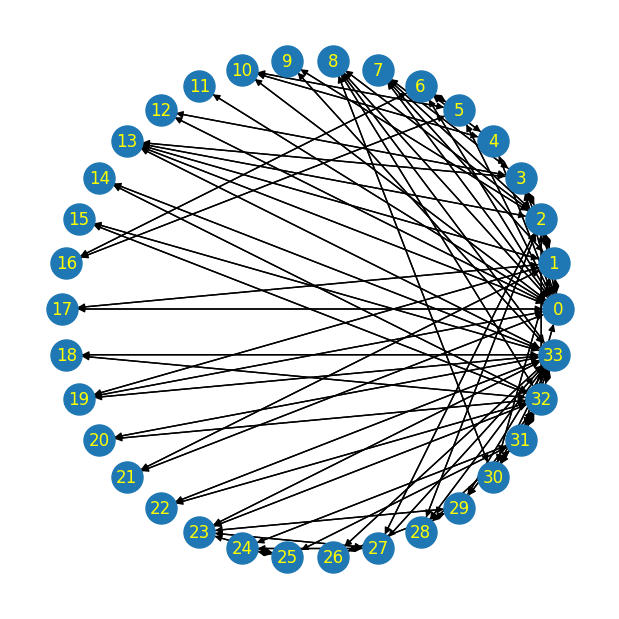

In [31]:
nx_graph = convert_jraph_to_networkx_graph(graph)
pos = nx.circular_layout(nx_graph)
plt.figure(figsize=(6, 6))
nx.draw(nx_graph, pos=pos, with_labels = True, node_size=500, font_color='yellow')

Define the GCN with the `GraphConvolution` layers we implemented:

In [35]:
def gcn_definition(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  """Defines a GCN for the karate club task.
  Args:
    graph: GraphsTuple the network processes.

  Returns:
    output graph with updated node values.
  """
  gn = GraphConvolution(
      update_node_fn=lambda n: jax.nn.relu(hk.Linear(8)(n)),
      add_self_edges=True)
  graph = gn(graph)

  # gn = GraphConvolution(
  #     update_node_fn=lambda n: jax.nn.relu(hk.Linear(4)(n)),
  #     add_self_edges=True)
  # graph = gn(graph)

  gn = GraphConvolution(
      update_node_fn=hk.Linear(2)) # output dim is 2 because we have 2 output classes.
  graph = gn(graph)
  return graph

Training and evaluation code:

In [33]:
def optimize_club(network: hk.Transformed, num_steps: int) -> jnp.ndarray:
  """Solves the karate club problem by optimizing the assignments of students."""
  zacharys_karate_club = get_zacharys_karate_club()
  labels = get_ground_truth_assignments_for_zacharys_karate_club()
  params = network.init(jax.random.PRNGKey(42), zacharys_karate_club)

  @jax.jit
  def predict(params: hk.Params) -> jnp.ndarray:
    decoded_graph = network.apply(params, zacharys_karate_club)
    return jnp.argmax(decoded_graph.nodes, axis=1)

  @jax.jit
  def prediction_loss(params: hk.Params) -> jnp.ndarray:
    decoded_graph = network.apply(params, zacharys_karate_club)
    # We interpret the decoded nodes as a pair of logits for each node.
    log_prob = jax.nn.log_softmax(decoded_graph.nodes)
    # The only two assignments we know a-priori are those of Mr. Hi (Node 0)
    # and John A (Node 33).
    return -(log_prob[0, 0] + log_prob[33, 1])

  opt_init, opt_update = optax.adam(1e-2)
  opt_state = opt_init(params)

  @jax.jit
  def update(params: hk.Params, opt_state) -> Tuple[hk.Params, Any]:
    """Returns updated params and state."""
    g = jax.grad(prediction_loss)(params)
    updates, opt_state = opt_update(g, opt_state)
    return optax.apply_updates(params, updates), opt_state

  @jax.jit
  def accuracy(params: hk.Params) -> jnp.ndarray:
    decoded_graph = network.apply(params, zacharys_karate_club)
    return jnp.mean(jnp.argmax(decoded_graph.nodes, axis=1) == labels)

  for step in range(num_steps):
    print(f"step {step} accuracy {accuracy(params).item():.2f}")
    params, opt_state = update(params, opt_state)

  return predict(params)

Let's train the GCN! We expect this model reach an accuracy of about 0.91.

In [34]:
network = hk.without_apply_rng(hk.transform(gcn_definition))
result_gcn = optimize_club(network, num_steps=15)

step 0 accuracy 0.50
step 1 accuracy 0.65
step 2 accuracy 0.97
step 3 accuracy 0.94
step 4 accuracy 0.94
step 5 accuracy 0.94
step 6 accuracy 0.94
step 7 accuracy 0.94
step 8 accuracy 0.97
step 9 accuracy 0.94
step 10 accuracy 0.94
step 11 accuracy 0.94
step 12 accuracy 0.94
step 13 accuracy 0.97
step 14 accuracy 0.97



Try modifying the model parameters to see if you can improve the accuracy!

You can also modify the dataset itself, and see how that influences model training.

$\color{#AA3939}{\text{A0.1:}}$ A higher accuracy can be achieved by introducing an additional hidden layer. We decided to add a layer with dimension 4 and therefore achieved the accuracy of 97%. For the upcoming experiments, we will revert the function to the initial setup (i.e., only two layers).

Node assignments predicted by the model at the end of training:

In [37]:
result_gcn

Array([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1], dtype=int32)

Visualize ground truth and predicted node assignments:

What do you think of the results?

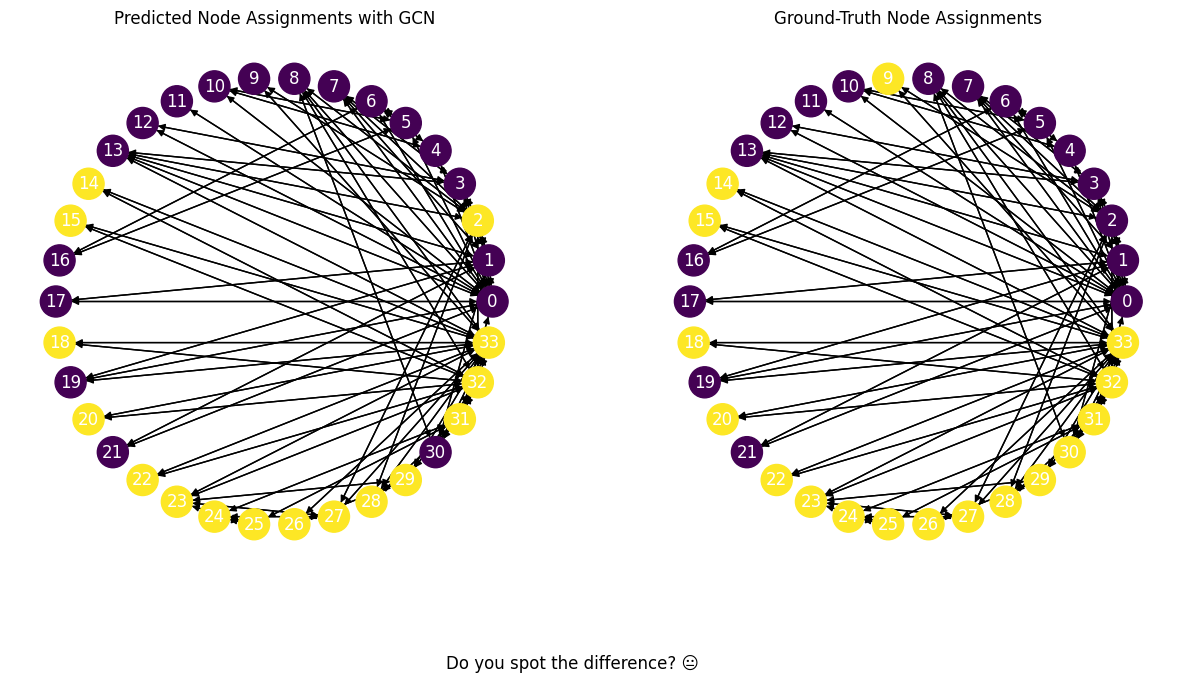

In [57]:
zacharys_karate_club = get_zacharys_karate_club()
nx_graph = convert_jraph_to_networkx_graph(zacharys_karate_club)
pos = nx.circular_layout(nx_graph)

fig = plt.figure(figsize=(15, 7))
ax1 = fig.add_subplot(121)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=result_gcn.tolist(),
    font_color='white')
ax1.title.set_text('Predicted Node Assignments with GCN')

gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
ax2 = fig.add_subplot(122)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=gt_labels.tolist(),
    font_color='white')
ax2.title.set_text('Ground-Truth Node Assignments')
fig.suptitle('Do you spot the difference? 😐', y=-0.01)

plt.show()

#### $\color{#AA3939}{\text{Questions}}$

$\color{#AA3939}{\text{Q1.1:}}$ Implement the iterative label propagation (ILP) algorithm from the SSL classes using GCN (hint: it can be expressed as chain of GCN layers, but remember to symmetrize the graph first), and motivate/describe your choices in the implementation.

$\color{#AA3939}{\text{A1.1:}}$ Based on prior work of [Kipf et al., 2016](https://arxiv.org/pdf/1609.02907), [Kipf et al., 2017](https://openreview.net/pdf?id=SygjB3AcYX), [Dong et al., 2020](https://arxiv.org/pdf/2010.12408), we start by defining the GCN layer propagation rule as:

$$
\begin{aligned}
H^{(l+1)} &= \sigma \left( \tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)} W^{(l)} \right),
\end{aligned}
$$
where $\tilde{A} = A + I_N$ is the adjacency matrix with added self-connections (self-edges) of the undirected graph and $I_N$ is the identity matrix, $\tilde{D}_{ii} = \sum_j \tilde{A}_{ij}$ is the degree matrix, $W^{(l)}$ is a trainable weight matrix at layer $l$, $\sigma(\cdot)$ is a non-linear activation function (e.g., ReLU), and $H^{(l)}$ are hidden representations at layer $l$.

Now, if we remove $\sigma(\cdot)$ (i.e., use identity mapping), we obtain:
$$
\begin{aligned}
H^{(l+1)} &= \tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)} W^{(l)}.
\end{aligned}
$$
If we further replace $W^{(l)}$ with a non-trainable, fixed, identity matrix, the previous equation simplifies to:
$$
\begin{aligned}
H^{(l+1)} &= \tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2} H^{(l)}.
\end{aligned}
$$

Now, by defining $\hat{A}=\tilde{D}^{-1/2} \tilde{A} \tilde{D}^{-1/2}$, we can write the propagation rule as:
$$
\begin{aligned}
H^{(l+1)} &= \hat{A} H^{(l)}.
\end{aligned}
$$

With this formulation, we can deviate from the original interpretation and consider $H^{(l)}$ not as hidden representations, but as propagated label representations, with $H^{(0)}=Y$, where $Y$ denotes the initial label matrix. If we now apply this rule iteratively for $l$ steps (i.e., over $l$ layers), we have:
$$
\begin{aligned}
H^{(l+1)} = \hat{A} H^{(l)} &\Longleftrightarrow H^{(l)} = \hat{A} H^{(l-1)} \\
          &\Longleftrightarrow H^{(l)} = \hat{A}^2 H^{(l-2)} \\
          &\Longleftrightarrow \cdots \\
          &\Longleftrightarrow H^{(l)} = \hat{A}^l H^{(0)} \\
          &\Longleftrightarrow H^{(l)} = \hat{A}^l Y,
\end{aligned}
$$
which corresponds to the iterative propagation of the initial labels. This can be seen as an ILP algorithm based on chaining GCN layers, and is exactly what we aimed for.

To translate this to code, we must first initialize the node features with the label matrix $Y$ (i.e., we set $H^{(0)} = Y$, as described above), so that the propagation is performed over labels rather than the original node features. Given that, we can implement our ILP procedure by creating `n_iter` `GraphConvolution` layers, each with `update_node_fn=lambda nodes: nodes` to enforce non-trainable (identity) weights, and with `add_self_edges=True` to include self-connections. In addition, we keep `symmetric_normalization=True` to match the normalization defined above.

We finally note that this implementation does not include clamping of labeled nodes (i.e., $y_{i}^{(k)} = y_i, \forall i \in \mathcal{V}_l$, where $\mathcal{V}_l$ is the set of labeled nodes), and therefore corresponds to a soft label propagation/label spreading algorithm, which additionally uses symmetric normalization instead of random walk normalization. To fully support the classical ILP formulation, it would be necessary to: (1) normalize the adjacency matrix as $D^{-1}A$ (which could be achieved by introducing a flag such as `rw_normalization` in the `GraphConvolution` function, analogous to `symmetric_normalization`) and (2) reset the known labels to their original values after each of the `n_iter` iterations. Since incorporating these changes would require modifications to the current `GraphConvolution` implementation and would deviate from both simply chaining these layers and the standard definition of GCN layers, we proceed with the approach described above.

In [ ]:
def get_ilp_graph() -> jraph.GraphsTuple:
    """Loads karate club graph and initializes soft label"""
    graph = get_zacharys_karate_club()
    nodes = jnp.zeros((len(graph.nodes), 2)) # initialize labels for students to zeros
    nodes = nodes.at[0].set(jnp.array([1.0, 0.0])) # set label 0 for first instructor
    nodes = nodes.at[33].set(jnp.array([0.0, 1.0])) # set label 1 for second instructor
    return graph._replace(nodes=nodes)

def ilp_gcn(graph: jraph.GraphsTuple, num_iter: int) -> jraph.GraphsTuple:
    """ILP based on GCN with identity weights, symmetric normalization, and self-connections."""
    gcn_layer = GraphConvolution(
        update_node_fn=lambda nodes: nodes,
        add_self_edges=True,
        symmetric_normalization=True
    )
    
    for _ in range(num_iter):
        graph = gcn_layer(graph)

    return graph

def ilp_algorithm(num_iters: int = 10) -> jnp.ndarray:
    """ILP algorithm with graph loading, propagation and class extraction."""
    graph = get_ilp_graph()
    graph = ilp_gcn(graph, num_iters)
    return jnp.argmax(graph.nodes, axis=1)

result_ilp = ilp_algorithm(num_iters=5)
result_ilp

Array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [59]:
gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
print(f"ILP accuracy: {jnp.mean(result_ilp == gt_labels)*100:.2f}%")

ILP accuracy: 97.06%


$\color{#AA3939}{\text{Q1.2:}}$ Compare accuracy of ILP and a GCN with MLP feature extraction on the Karate club dataset. (remember that \{0,1\} labels do not have a meaning for ILP)

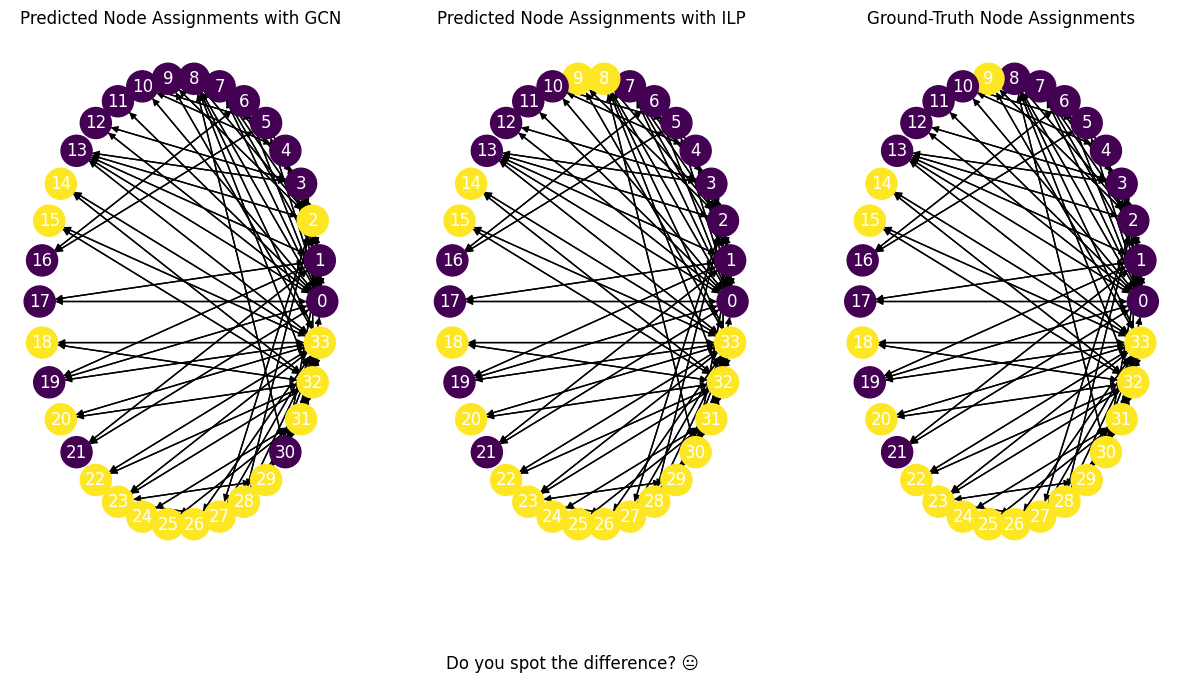

In [60]:
zacharys_karate_club = get_zacharys_karate_club()
nx_graph = convert_jraph_to_networkx_graph(zacharys_karate_club)
pos = nx.circular_layout(nx_graph)

fig = plt.figure(figsize=(15, 7))
ax1 = fig.add_subplot(131)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=result_gcn.tolist(),
    font_color='white')
ax1.title.set_text('Predicted Node Assignments with GCN')

gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
ax2 = fig.add_subplot(132)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=result_ilp.tolist(),
    font_color='white')
ax2.title.set_text('Predicted Node Assignments with ILP')


gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
ax3 = fig.add_subplot(133)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=gt_labels.tolist(),
    font_color='white')
ax3.title.set_text('Ground-Truth Node Assignments')

fig.suptitle('Do you spot the difference? 😐', y=-0.01)

plt.show()

$\color{#AA3939}{\text{A1.2:}}$ From the upper plot, we observe that the results are mostly identical, with the GCN making prediction errors on nodes 2, 8, and 30, while the ILP algorithm (with five iterations) makes an error only on node 8. We can now also compare the corresponding accuracy values.

In [ ]:
gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
print(f"GCN accuracy: {jnp.mean(result_gcn == gt_labels)*100:.2f}%")

GCN accuracy: 91.18%
ILP accuracy: 97.06%


The accuracy scores confirm the observations from the plot and indicate that the ILP algorithm better classifies the nodes than the GCN. As a final experiment, we can examine how the `num_iters` parameter affects ILP performance and how it compares to GCN under those cases.

In [69]:
gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
print(f"GCN accuracy: {jnp.mean(result_gcn == gt_labels)*100:.2f}%")

for num_iter in [5, 10, 20, 30, 40, 50]:
    result_ilp = ilp_algorithm(num_iters=num_iter)
    print(f"ILP with {num_iter} iterations accuracy: {jnp.mean(result_ilp == gt_labels)*100:.2f}%")

GCN accuracy: 91.18%
ILP with 5 iterations accuracy: 97.06%
ILP with 10 iterations accuracy: 94.12%
ILP with 20 iterations accuracy: 94.12%
ILP with 30 iterations accuracy: 85.29%
ILP with 40 iterations accuracy: 64.71%
ILP with 50 iterations accuracy: 50.00%


These results reveal that the performance of the ILP algorithm strongly depends on the number of iterations. As the number of iterations increases, the accuracy gradually decreases. Because of this, we will plot how ILP accuracy evolves with respect to the number of iterations (alongside the GCN accuracy as a dashed reference line) to give final conclusion.

Text(0.5, 1.0, 'ILP accuracy as a function of number of iterations')

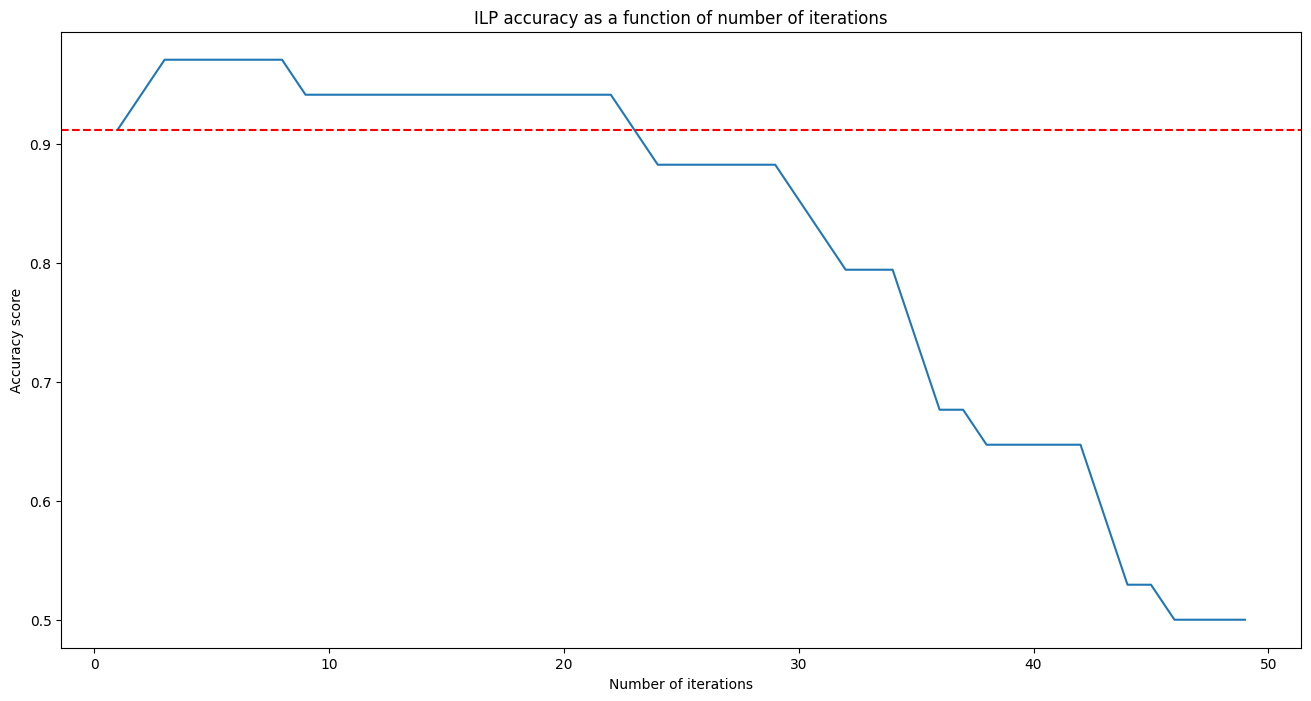

In [68]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

num_iters = jnp.arange(1, 50)
ilp_accs = []
for num_iter in num_iters:
    result_ilp = ilp_algorithm(num_iters=num_iter)
    ilp_accs.append(jnp.mean(result_ilp == gt_labels))

ax.plot(num_iters, ilp_accs)
ax.axhline(y=jnp.mean(result_gcn == gt_labels), color='red', linestyle='--')
ax.set_xlabel("Number of iterations")
ax.set_ylabel("Accuracy score")
ax.set_title("ILP accuracy as a function of number of iterations")

The plot shows that ILP achieves higher accuracy than GCN when the num_iters $\leq 23$, while GCN outperforms ILP beyond this point. Overall, the better performance between the two depends on the choice of the `num_iters` hyperparameter for the ILP algorithm: ILP outperforms GCN by up to 6% for smaller `num_iters` values, while GCN achieves significantly higher accuracy for larger values of it.

# Graph Attention (GAT) Layer

While the GCN we covered in the previous section can learn meaningful representations, it also has some shortcomings. Can you think of any?

In the GCN layer, the messages from all its neighbours and the node itself are equally weighted. This may lead to loss of node-specific information. E.g., consider the case when a set of nodes shares the same set of neighbors, and start out with different node features. Then because of averaging, their resulting output features would be the same. Adding self-edges mitigates this issue by a small amount, but this problem is magnified with increasing number of GCN layers and number of edges connecting to a node.

The graph attention (GAT) mechanism, as proposed by [Velickovic et al. ( 2017)](https://arxiv.org/abs/1710.10903), allows the network to learn how to weigh / assign importance to the node features from the neighbourhood when computing the new node features. This is very similar to the idea of using attention in Transformers, which were introduced in [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762).

(One could even argue that Transformers are graph attention networks operating on the special case of fully-connected graphs.)

In the figure below, $\vec{h}$ are the node features and $\vec{\alpha}$ are the learned attention weights.



<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/gat1.png" width="400px">

Figure Credit: [Velickovic et al. ( 2017)](https://arxiv.org/abs/1710.10903).
(Detail: This image is showing multi-headed attention with 3 heads, each color corresponding to a different head. At the end, an aggregation function is applied over all the heads.)

To obtain the output node features of the GAT layer, we compute:

$$ \vec{h}'_i = \sum _{j \in \mathcal{N}(i)}\alpha_{ij} \mathbf{W} \vec{h}_j$$
Here, $\mathbf{W}$ is a weight matrix which performs a linear transformation on the input.





How do we obtain $\alpha$, or in other words, learn what to pay attention to?

Intuitively, the attention coefficient $\alpha_{ij}$ should rely on both the transformed features from nodes $i$ and $j$. So let's first define an attention mechanism function $\mathrm{attention\_fn}$ that computes the intermediary attention coefficients $e_{ij}$:
$$ e_{ij} = \mathrm{attention\_fn}(\mathbf{W}\vec{h}_i, \mathbf{W}\vec{h}_j)$$

To obtain normalized attention weights $\alpha$, we apply a softmax:
$$\alpha_{ij} = \frac{\exp(e_{ij})}{\sum _{j \in \mathcal{N}(i)}\exp(e_{ij})}$$

For the function $a$, the authors of the GAT paper chose to concatenate the transformed node features (denoted by $||$) and apply a single-layer feedforward network, parameterized by a weight vector $\vec{\mathbf{a}}$ and with LeakyRelu as non-linearity.

In the implementation below, we refer to $\mathbf{W}$ as `attention_query_fn` and $att\_fn$ as `attention_logit_fn`.

$$\mathrm{attention\_fn}(\mathbf{W}\vec{h}_i, \mathbf{W}\vec{h}_j) =  \text{LeakyReLU}(\vec{\mathbf{a}}(\mathbf{W}\vec{h}_i || \mathbf{W}\vec{h}_j))$$

The figure below summarizes this attention mechanism visually.

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/gat2.png" width="300px">

Figure Credit: Petar Velickovic.
<!-- $\sum_{j \in \mathcal{N}(i)}\vec{\alpha}_{ij} \stackrel{!}{=}
1 $  -->



In [38]:
# GAT implementation adapted from https://github.com/deepmind/jraph/blob/master/jraph/_src/models.py#L442.
def GAT(attention_query_fn: Callable,
        attention_logit_fn: Callable,
        node_update_fn: Optional[Callable] = None,
        add_self_edges: bool = True) -> Callable:
  """Returns a method that applies a Graph Attention Network layer.

  Graph Attention message passing as described in
  https://arxiv.org/pdf/1710.10903.pdf. This model expects node features as a
  jnp.array, may use edge features for computing attention weights, and
  ignore global features. It does not support nests.
  Args:
    attention_query_fn: function that generates attention queries from sender
      node features.
    attention_logit_fn: function that converts attention queries into logits for
      softmax attention.
    node_update_fn: function that updates the aggregated messages. If None, will
      apply leaky relu and concatenate (if using multi-head attention).

  Returns:
    A function that applies a Graph Attention layer.
  """
  # pylint: disable=g-long-lambda
  if node_update_fn is None:
    # By default, apply the leaky relu and then concatenate the heads on the
    # feature axis.
    node_update_fn = lambda x: jnp.reshape(
        jax.nn.leaky_relu(x), (x.shape[0], -1))

  def _ApplyGAT(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
    """Applies a Graph Attention layer."""
    nodes, edges, receivers, senders, _, _, _ = graph
    # Equivalent to the sum of n_node, but statically known.
    try:
      sum_n_node = nodes.shape[0]
    except IndexError:
      raise IndexError('GAT requires node features')

    # Pass nodes through the attention query function to transform
    # node features, e.g. with an MLP.
    nodes = attention_query_fn(nodes)

    total_num_nodes = tree.tree_leaves(nodes)[0].shape[0]
    if add_self_edges:
      # We add self edges to the senders and receivers so that each node
      # includes itself in aggregation.
      receivers, senders = add_self_edges_fn(receivers, senders,
                                             total_num_nodes)

    # We compute the softmax logits using a function that takes the
    # embedded sender and receiver attributes.
    sent_attributes = nodes[senders]
    received_attributes = nodes[receivers]
    att_softmax_logits = attention_logit_fn(sent_attributes,
                                            received_attributes, edges)

    # Compute the attention softmax weights on the entire tree.
    att_weights = jraph.segment_softmax(
        att_softmax_logits, segment_ids=receivers, num_segments=sum_n_node)

    # Apply attention weights.
    messages = sent_attributes * att_weights
    # Aggregate messages to nodes.
    nodes = jax.ops.segment_sum(messages, receivers, num_segments=sum_n_node)

    # Apply an update function to the aggregated messages.
    nodes = node_update_fn(nodes)

    return graph._replace(nodes=nodes)

  # pylint: enable=g-long-lambda
  return _ApplyGAT

#### Test GAT Layer

In [39]:
def attention_logit_fn(sender_attr: jnp.ndarray, receiver_attr: jnp.ndarray,
                       edges: jnp.ndarray) -> jnp.ndarray:
  del edges
  x = jnp.concatenate((sender_attr, receiver_attr), axis=1)
  return hk.Linear(1)(x)


gat_layer = GAT(
    attention_query_fn=lambda n: hk.Linear(8)
    (n),  # Applies W to the node features
    attention_logit_fn=attention_logit_fn,
    node_update_fn=None,
    add_self_edges=True,
)

In [40]:
graph = build_toy_graph()
network = hk.without_apply_rng(hk.transform(gat_layer))
params = network.init(jax.random.PRNGKey(42), graph)
out_graph = network.apply(params, graph)
out_graph.nodes

Array([[-2.1254564e-02,  2.4042883e+00, -4.0143323e-03, -2.0577878e-02,
         1.8933861e+00,  1.1548430e+00, -5.3817675e-02, -1.0350263e-02],
       [-6.7768167e-03,  7.6658463e-01, -1.2799320e-03, -6.5610623e-03,
         6.0368830e-01,  3.6821079e-01, -1.7159257e-02, -3.3000836e-03],
       [-2.1208903e-02,  2.3991234e+00, -4.0057087e-03, -2.0533672e-02,
         1.8893188e+00,  1.1523622e+00, -5.3702068e-02, -1.0328028e-02],
       [-1.7733721e-02,  2.0060153e+00, -3.3493536e-03, -1.7169129e-02,
         1.5797446e+00,  9.6354198e-01, -4.4902720e-02, -8.6357296e-03]],      dtype=float32)

#### Train GAT Model on Karate Club Dataset
We will now repeat the karate club experiment with a GAT network.

In [41]:
def gat_definition(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  """Defines a GAT network for the karate club node classification task.

  Args:
    graph: GraphsTuple the network processes.

  Returns:
    output graph with updated node values.
  """

  def _attention_logit_fn(sender_attr: jnp.ndarray, receiver_attr: jnp.ndarray,
                          edges: jnp.ndarray) -> jnp.ndarray:
    del edges
    x = jnp.concatenate((sender_attr, receiver_attr), axis=1)
    return hk.Linear(1)(x)

  gn = GAT(
      attention_query_fn=lambda n: hk.Linear(8)(n),
      attention_logit_fn=_attention_logit_fn,
      node_update_fn=None,
      add_self_edges=True)
  graph = gn(graph)

  gn = GAT(
      attention_query_fn=lambda n: hk.Linear(8)(n),
      attention_logit_fn=_attention_logit_fn,
      node_update_fn=hk.Linear(2),
      add_self_edges=True)
  graph = gn(graph)
  return graph

Let's train the model!

We expect the model to reach an accuracy of about 0.97.

In [42]:
network = hk.without_apply_rng(hk.transform(gat_definition))
result = optimize_club(network, num_steps=15)

step 0 accuracy 0.50
step 1 accuracy 0.94
step 2 accuracy 0.94
step 3 accuracy 0.94
step 4 accuracy 0.97
step 5 accuracy 0.97
step 6 accuracy 0.97
step 7 accuracy 0.97
step 8 accuracy 0.97
step 9 accuracy 0.97
step 10 accuracy 1.00
step 11 accuracy 1.00
step 12 accuracy 1.00
step 13 accuracy 0.97
step 14 accuracy 0.97


The final node assignment predicted by the trained model:

In [43]:
result

Array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

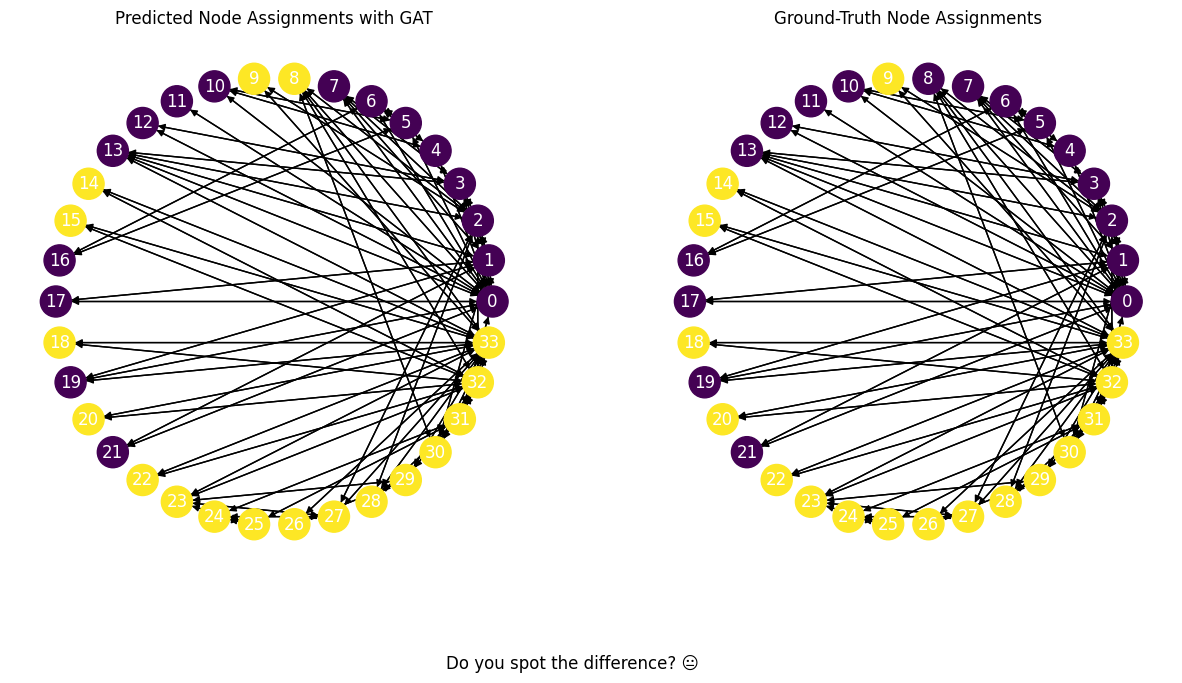

In [44]:
zacharys_karate_club = get_zacharys_karate_club()
nx_graph = convert_jraph_to_networkx_graph(zacharys_karate_club)
pos = nx.circular_layout(nx_graph)

fig = plt.figure(figsize=(15, 7))
ax1 = fig.add_subplot(121)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=result.tolist(),
    font_color='white')
ax1.title.set_text('Predicted Node Assignments with GAT')

gt_labels = get_ground_truth_assignments_for_zacharys_karate_club()
ax2 = fig.add_subplot(122)
nx.draw(
    nx_graph,
    pos=pos,
    with_labels=True,
    node_size=500,
    node_color=gt_labels.tolist(),
    font_color='white')
ax2.title.set_text('Ground-Truth Node Assignments')
fig.suptitle('Do you spot the difference? 😐', y=-0.01)
plt.show()

$\color{#AA3939}{\text{A0.2:}}$ It seems that the result with GAT is equivalent to ILP alorithm's result, and therefore better than GCN's one.

# Graph Classification on MUTAG (Molecules)

In the previous section, we used our GCN and GAT networks on a node classification problem. Now, let's use the same model architectures on a **graph classification task**.

The main difference from our previous setup is that instead of observing individual node latents, we are now attempting to summarize them into one embedding vector, representative of the entire graph, which we then use to predict the class of this graph.

We will do this on one of the most common tasks of this type -- **molecular property prediction**, where molecules are represented as graphs. Nodes correspond to atoms, and edges represent the bonds between them.

We will use the **MUTAG** dataset for this example, a common dataset from the [TUDatasets](https://chrsmrrs.github.io/datasets/) collection.

We have converted this dataset to be compatible with jraph and will download it in the cell below.

Citation for TUDatasets: [Morris, Christopher, et al. Tudataset: A collection of benchmark datasets for learning with graphs. arXiv preprint arXiv:2007.08663. 2020.](https://chrsmrrs.github.io/datasets/)


In [45]:
# UNCOMMENT FOR LINUX
# # Download jraph version of MUTAG.
# !wget -P /tmp/ https://storage.googleapis.com/dm-educational/assets/graph-nets/jraph_datasets/mutag.pickle
# with open('/tmp/mutag.pickle', 'rb') as f:
#   mutag_ds = pickle.load(f)

# WORKING VERSION FOR WINDOWS. COMMENT FOR LINUX
import urllib.request, pickle, os

# Download jraph version of MUTAG.
os.makedirs("tmp", exist_ok=True)
url = "https://storage.googleapis.com/dm-educational/assets/graph-nets/jraph_datasets/mutag.pickle"
file_path = "tmp/mutag.pickle"
# urllib.request.urlretrieve(url, file_path)

# Load dataset.
with open(file_path, "rb") as f:
    mutag_ds = pickle.load(f)

The dataset is saved as a list of examples, each example is a dictionary containing an input_graph and its corresponding target.

In [46]:
len(mutag_ds)

188

In [47]:
# Inspect the first graph
g = mutag_ds[0]['input_graph']
print(f'Number of nodes: {g.n_node[0]}')
print(f'Number of edges: {g.n_edge[0]}')
print(f'Node features shape: {g.nodes.shape}')
print(f'Edge features shape: {g.edges.shape}')

Number of nodes: 17
Number of edges: 38
Node features shape: (17, 7)
Edge features shape: (38, 4)


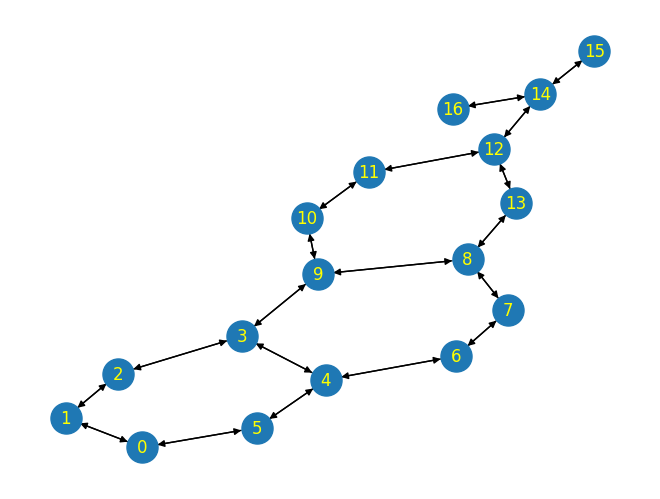

In [48]:
draw_jraph_graph_structure(g)

In [49]:
# Target for first graph
print(f"Target: {mutag_ds[0]['target']}")

Target: [1]


We see that there are 188 graphs, to be classified in one of 2 classes, representing "their mutagenic effect on a specific gram negative bacterium". Node features represent the 1-hot encoding of the atom type (0=C, 1=N, 2=O, 3=F, 4=I, 5=Cl, 6=Br). Edge features (`edge_attr`) represent the bond type, which we will here ignore.

Let's split the dataset to use the first 150 graphs as the training set (and the rest as the test set).

In [50]:
train_mutag_ds = mutag_ds[:150]
test_mutag_ds = mutag_ds[150:]

#### Padding Graphs to Speed Up Training

Since jax recompiles the program for each graph size, training would take a long time due to recompilation for different graph sizes. To address that, we pad the number of nodes and edges in the graphs to nearest power of two. Since jax maintains a cache
of compiled programs, the compilation cost is amortized.

In [51]:
# Adapted from https://github.com/deepmind/jraph/blob/master/jraph/ogb_examples/train.py
def _nearest_bigger_power_of_two(x: int) -> int:
  """Computes the nearest power of two greater than x for padding."""
  y = 2
  while y < x:
    y *= 2
  return y

def pad_graph_to_nearest_power_of_two(
    graphs_tuple: jraph.GraphsTuple) -> jraph.GraphsTuple:
  """Pads a batched `GraphsTuple` to the nearest power of two.
  For example, if a `GraphsTuple` has 7 nodes, 5 edges and 3 graphs, this method
  would pad the `GraphsTuple` nodes and edges:
    7 nodes --> 8 nodes (2^3)
    5 edges --> 8 edges (2^3)
  And since padding is accomplished using `jraph.pad_with_graphs`, an extra
  graph and node is added:
    8 nodes --> 9 nodes
    3 graphs --> 4 graphs
  Args:
    graphs_tuple: a batched `GraphsTuple` (can be batch size 1).
  Returns:
    A graphs_tuple batched to the nearest power of two.
  """
  # Add 1 since we need at least one padding node for pad_with_graphs.
  pad_nodes_to = _nearest_bigger_power_of_two(jnp.sum(graphs_tuple.n_node)) + 1
  pad_edges_to = _nearest_bigger_power_of_two(jnp.sum(graphs_tuple.n_edge))
  # Add 1 since we need at least one padding graph for pad_with_graphs.
  # We do not pad to nearest power of two because the batch size is fixed.
  pad_graphs_to = graphs_tuple.n_node.shape[0] + 1
  return jraph.pad_with_graphs(graphs_tuple, pad_nodes_to, pad_edges_to,
                               pad_graphs_to)

#### Graph Network Model Definition

We will use `jraph.GraphNetwork()` to build our graph model. The `GraphNetwork` architecture is defined in [Battaglia et al. (2018)](https://arxiv.org/pdf/1806.01261.pdf).

We first define update functions for nodes, edges, and the full graph (global). We will use MLP blocks for all three.

In [52]:
# Adapted from https://github.com/deepmind/jraph/blob/master/jraph/ogb_examples/train.py
@jraph.concatenated_args
def edge_update_fn(feats: jnp.ndarray) -> jnp.ndarray:
  """Edge update function for graph net."""
  net = hk.Sequential(
      [hk.Linear(128), jax.nn.relu,
       hk.Linear(128)])
  return net(feats)

@jraph.concatenated_args
def node_update_fn(feats: jnp.ndarray) -> jnp.ndarray:
  """Node update function for graph net."""
  net = hk.Sequential(
      [hk.Linear(128), jax.nn.relu,
       hk.Linear(128)])
  return net(feats)

@jraph.concatenated_args
def update_global_fn(feats: jnp.ndarray) -> jnp.ndarray:
  """Global update function for graph net."""
  # MUTAG is a binary classification task, so output pos neg logits.
  net = hk.Sequential(
      [hk.Linear(128), jax.nn.relu,
       hk.Linear(2)])
  return net(feats)

def net_fn(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  # Add a global paramater for graph classification.
  graph = graph._replace(globals=jnp.zeros([graph.n_node.shape[0], 1]))
  embedder = jraph.GraphMapFeatures(
      hk.Linear(128), hk.Linear(128), hk.Linear(128))
  net = jraph.GraphNetwork(
      update_node_fn=node_update_fn,
      update_edge_fn=edge_update_fn,
      update_global_fn=update_global_fn)
  return net(embedder(graph))

#### Loss and Accuracy Function
Define the classification cross-entropy loss and accuracy function.

In [53]:
def compute_loss(params: hk.Params, graph: jraph.GraphsTuple, label: jnp.ndarray,
                 net: jraph.GraphsTuple) -> Tuple[jnp.ndarray, jnp.ndarray]:
  """Computes loss and accuracy."""
  pred_graph = net.apply(params, graph)
  preds = jax.nn.log_softmax(pred_graph.globals)
  targets = jax.nn.one_hot(label, 2)

  # Since we have an extra 'dummy' graph in our batch due to padding, we want
  # to mask out any loss associated with the dummy graph.
  # Since we padded with `pad_with_graphs` we can recover the mask by using
  # get_graph_padding_mask.
  mask = jraph.get_graph_padding_mask(pred_graph)

  # Cross entropy loss.
  loss = -jnp.mean(preds * targets * mask[:, None])

  # Accuracy taking into account the mask.
  accuracy = jnp.sum(
      (jnp.argmax(pred_graph.globals, axis=1) == label) * mask) / jnp.sum(mask)
  return loss, accuracy

#### Training and Evaluation Functions

In [54]:
# Adapted from https://github.com/deepmind/jraph/blob/master/jraph/ogb_examples/train.py
def train(dataset: List[Dict[str, Any]], num_train_steps: int) -> hk.Params:
  """Training loop."""

  # Transform impure `net_fn` to pure functions with hk.transform.
  net = hk.without_apply_rng(hk.transform(net_fn))
  # Get a candidate graph and label to initialize the network.
  graph = dataset[0]['input_graph']

  # Initialize the network.
  params = net.init(jax.random.PRNGKey(42), graph)
  # Initialize the optimizer.
  opt_init, opt_update = optax.adam(1e-4)
  opt_state = opt_init(params)

  compute_loss_fn = functools.partial(compute_loss, net=net)
  # We jit the computation of our loss, since this is the main computation.
  # Using jax.jit means that we will use a single accelerator. If you want
  # to use more than 1 accelerator, use jax.pmap. More information can be
  # found in the jax documentation.
  compute_loss_fn = jax.jit(jax.value_and_grad(
      compute_loss_fn, has_aux=True))

  for idx in range(num_train_steps):
    graph = dataset[idx % len(dataset)]['input_graph']
    label = dataset[idx % len(dataset)]['target']
    # Jax will re-jit your graphnet every time a new graph shape is encountered.
    # In the limit, this means a new compilation every training step, which
    # will result in *extremely* slow training. To prevent this, pad each
    # batch of graphs to the nearest power of two. Since jax maintains a cache
    # of compiled programs, the compilation cost is amortized.
    graph = pad_graph_to_nearest_power_of_two(graph)

    # Since padding is implemented with pad_with_graphs, an extra graph has
    # been added to the batch, which means there should be an extra label.
    label = jnp.concatenate([label, jnp.array([0])])

    (loss, acc), grad = compute_loss_fn(params, graph, label)
    updates, opt_state = opt_update(grad, opt_state, params)
    params = optax.apply_updates(params, updates)
    if idx % 50 == 0:
      print(f'step: {idx}, loss: {loss}, acc: {acc}')
  print('Training finished')
  return params

In [55]:
def evaluate(dataset: List[Dict[str, Any]],
             params: hk.Params) -> Tuple[jnp.ndarray, jnp.ndarray]:
  """Evaluation Script."""
  # Transform impure `net_fn` to pure functions with hk.transform.
  net = hk.without_apply_rng(hk.transform(net_fn))
  # Get a candidate graph and label to initialize the network.
  graph = dataset[0]['input_graph']
  accumulated_loss = 0
  accumulated_accuracy = 0
  compute_loss_fn = jax.jit(functools.partial(compute_loss, net=net))
  for idx in range(len(dataset)):
    graph = dataset[idx]['input_graph']
    label = dataset[idx]['target']
    graph = pad_graph_to_nearest_power_of_two(graph)
    label = jnp.concatenate([label, jnp.array([0])])
    loss, acc = compute_loss_fn(params, graph, label)
    accumulated_accuracy += acc
    accumulated_loss += loss
    if idx % 100 == 0:
      print(f'Evaluated {idx + 1} graphs')
  print('Completed evaluation.')
  loss = accumulated_loss / idx
  accuracy = accumulated_accuracy / idx
  print(f'Eval loss: {loss}, accuracy {accuracy}')
  return loss, accuracy

In [56]:
params = train(train_mutag_ds, num_train_steps=500)

step: 0, loss: 0.28438910841941833, acc: 0.0
step: 50, loss: 0.0006321418331936002, acc: 1.0
step: 100, loss: 0.0013380241580307484, acc: 1.0
step: 150, loss: 0.04702804237604141, acc: 1.0
step: 200, loss: 0.041739653795957565, acc: 1.0
step: 250, loss: 0.0028245325665920973, acc: 1.0
step: 300, loss: 0.047925930470228195, acc: 1.0
step: 350, loss: 0.03225915506482124, acc: 1.0
step: 400, loss: 0.0030686105601489544, acc: 1.0
step: 450, loss: 0.036227963864803314, acc: 1.0
Training finished


In [57]:
evaluate(test_mutag_ds, params)

Evaluated 1 graphs
Completed evaluation.
Eval loss: 0.14461463689804077, accuracy 0.7567567825317383


(Array(0.14461464, dtype=float32), Array(0.7567568, dtype=float32))

We converge at ~76% test accuracy. We could of course further tune the parameters to improve this result.

### $\color{#AA3939}{\text{Questions}}$

$\color{#AA3939}{\text{Q2.1:}}$ One of the main use cases of GNNs is feature extraction. Use the network you trained in the previous section to exctract embeddings (i.e. vectorial representations) of each MUTAG graph.

$\color{#AA3939}{\text{A2.1:}}$ To extract graph embeddings, we will replace `update_global_fn` with a new function called `update_embedding_fn` that removes the final classifier layer (i.e., `Linear(2)`), and therefore keeps the structure of `Linear(128)` followed by `ReLU` activation. We extract embeddings before the final classifier layer because the 128-dimensional hidden representation contains richer information about the graph, whereas the `Linear(2)` output collapses everything into just two values (one per class), and therefore discards most of the learned representation. With this modification, we can moreover use trained weights from `node_update_fn`, `edge_update_fn`, and the first part of `update_global_fn` (i.e., first layer), and output a 128-dimensional representation (i.e., embedding). Once done, we will run each graph through this modified network and extract the embeddings from `globals`.

In [ ]:
@jraph.concatenated_args
def update_embedding_fn(feats: jnp.ndarray) -> jnp.ndarray:
    """Global update function for graph net without the classifier layer"""
    net = hk.Sequential([hk.Linear(128), jax.nn.relu])
    return net(feats)

def net_fn_embedding(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
    """Analogous to net_fn function but uses update_embedding_fn for update_global_fn"""
    graph = graph._replace(globals=jnp.zeros([graph.n_node.shape[0], 1]))
    embedder = jraph.GraphMapFeatures(hk.Linear(128), hk.Linear(128), hk.Linear(128))
    net = jraph.GraphNetwork(
        update_node_fn=node_update_fn,
        update_edge_fn=edge_update_fn,
        update_global_fn=update_embedding_fn) # replaced update_global_fn
    return net(embedder(graph))

def get_embeddings(dataset, params):
    """Function for extracting embeddings for every graph in the dataset"""
    net = hk.without_apply_rng(hk.transform(net_fn_embedding))
    embeddings, labels = [], []
    for sample in dataset:
        graph = pad_graph_to_nearest_power_of_two(sample['input_graph'])
        pred_graph = net.apply(params, graph)
        mask = jraph.get_graph_padding_mask(pred_graph)
        embeddings.append(pred_graph.globals[mask][0]) # extract embeddings from globals
        labels.append(int(sample['target'][0]))
    return onp.array(embeddings), onp.array(labels)

embeddings, gt_labels = get_embeddings(mutag_ds, params)
assert embeddings.shape == (len(mutag_ds), 128), "Embeddings shape are incorrect!"


$\color{#AA3939}{\text{Q2.2:}}$ Use the extracted embedding to cluster the graphs, and visualize the clustering. Does it agree with the class labels? Why (or why not)?

$\color{#AA3939}{\text{A2.2:}}$ Here, we first use the extracted embeddings and apply `KMeans` to cluster all the graphs into two clusters. We will then compute accuracy score by comparing the labels produced by `KMeans` with the class labels. In addition, since `scikit.KMeans` includes a stochastic parameter `random_state`, we will repeat the experiment multiple times to get better estimate.

We would like to note that we were initially unsure whether the task required splitting the embeddings into training and testing sets, fitting on the training embeddings and evaluating on the test embeddings, or simply clustering all embeddings at once. We interpreted the goal of the task as assessing whether the extracted embeddings contain sufficient information to cluster the graphs using `KMeans`, and therefore proceeded with the latter approach.

In [113]:
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

embeddings, gt_labels = get_embeddings(mutag_ds, params)

for rs in [0, 21, 42, 78]:
    kmeans_labels = KMeans(n_clusters=2, random_state=rs).fit(embeddings).labels_
    # KMeans labels are arbitrary so we must flip them if necessary
    acc = accuracy_score(gt_labels, kmeans_labels)
    acc_flipped = accuracy_score(gt_labels, 1-kmeans_labels)
    kmeans_acc = max(acc, acc_flipped)
    if acc_flipped > acc:
        kmeans_labels = 1 - kmeans_labels
    print(f"KMeans clustering accuracy (random state {rs}): {kmeans_acc*100:.2f}%")


KMeans clustering accuracy (random state 0): 69.68%
KMeans clustering accuracy (random state 21): 83.51%
KMeans clustering accuracy (random state 42): 69.68%
KMeans clustering accuracy (random state 78): 83.51%


We observe that the accuracy scores vary between 69.68% and 83.51%. Overall, this level of accuracy is relatively high and satisfactory. We will now proceed with the visualization and will return to comment on the accuracy afterward. 

In order to visualize clustering, we will project the 128-dimensional embeddings into 2D using t-SNE projection. We will show both the plots corresponding to `KMeans` predictions and ground truth labels, with each point colored by `KMeans` cluster assignment and ground truth label, respectively.

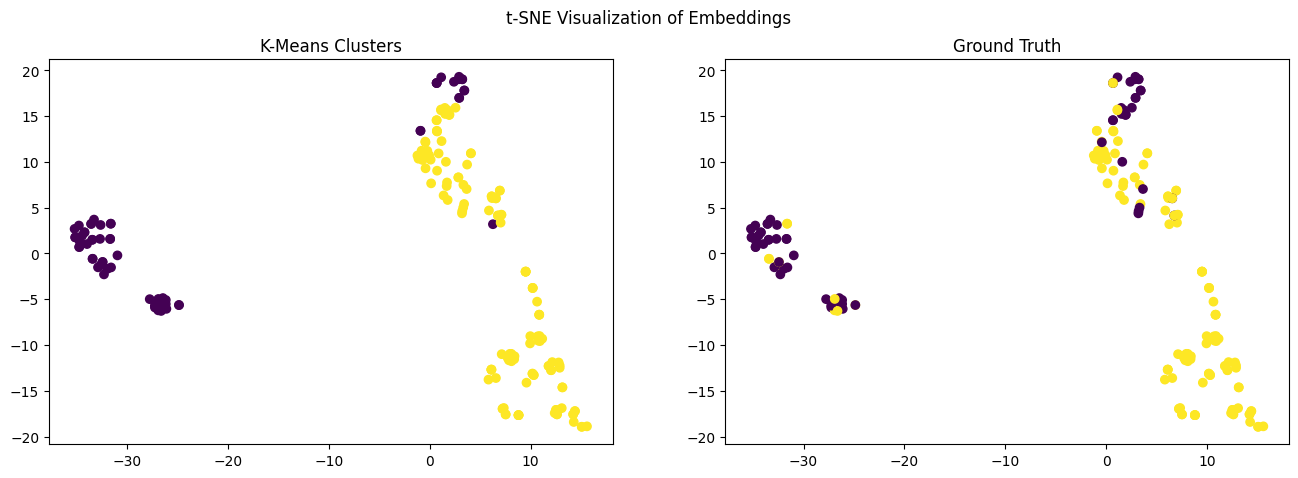

In [115]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# pca = PCA(n_components=2)
# emb_pca = pca.fit_transform(embeddings)

# fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# for ax, labels, title in zip(axes, [kmeans_labels, gt_labels], ['K-Means Clusters', 'Ground Truth']):
#     ax.scatter(emb_pca[:, 0], emb_pca[:, 1], c=labels)
#     ax.set_title(title)
# fig.suptitle("PCA Visualization of Embeddings")
# plt.show()

tsne = TSNE(n_components=2, random_state=0, perplexity=20)
emb_tsne = tsne.fit_transform(embeddings)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, labels, title in zip(axes, [kmeans_labels, gt_labels], ['K-Means Clusters', 'Ground Truth']):
    ax.scatter(emb_tsne[:, 0], emb_tsne[:, 1], c=labels)
    ax.set_title(title)
fig.suptitle("t-SNE Visualization of Embeddings")
plt.show()

We must first note that if the embeddings are well learned and contextualized, then the samples belonging to the same class should be grouped together in the 2D projection space. We can now focus on the Ground Truth plot and observe two clearly separated groups, which indeed indicates that the embeddings capture meaningful information. Most samples from the same class are grouped within the same region, although a small number of them appear in regions dominated by the opposite class. If we now look at the `KMeans` plot, we can observe that this small number of points corresponds to the misclustered samples. Even though `KMeans` correctly clusters some of them (e.g., points roughly between 15 and 20 on the y-axis and 0–5 on the x-axis), the majority are assigned to the wrong cluster. This suggests that the corresponding embeddings of these samples are not sufficiently expressive and discriminative, because they are positioned close to embeddings of the opposite class, which ultimately leads to incorrect clustering. We assume that this is due to the model not learning strong enough representations for these particular samples.

Overall, both quantitatively (i.e., aformentioned high accuracy) and qualitatively, the results show that the embeddings are meaningful and can be used for clustering. As a final note, we can say that the predicted labels largely agree with the ground truth class labels.

# Link prediction on CORA (Citation Network)

The final problem type we will explore is **link prediction**, an instance of an **edge-level** task. Given a graph, our goal is to predict whether a certain edge $(u,v)$ should be present or not. This is often useful in the recommender system settings (e.g., propose new friends in a social network, propose a movie to a user).

As before, the first step is to obtain node latents $h_i$ using a GNN. In this context we will use the autoencoder language and call this GNN **encoder**. Then, we learn a binary classifier $f: (h_i, h_j) \to z_{i,j}$ (**decoder**), predicting if an edge $(i,j)$ should exist or not. While we could use a more elaborate decoder (e.g., an MLP), a common approach we will also use here is to focus on obtaining good node embeddings, and for the decoder simply use the similarity between node latents, i.e. $z_{i,j} = h_i^T h_j$.


For this problem we will use the [**Cora** dataset](https://linqs.github.io/linqs-website/datasets/#cora), a citation graph containing 2708 scientific publications. For each publication we have a 1433-dimensional feature vector, which is a bag-of-words representation (with a small, fixed dictionary) of the paper text. The edges in this graph represent citations, and are commonly treated as undirected. Each paper is in one of seven topics (classes) so you can also use this dataset for node classification.

Similar to MUTAG, we have converted this dataset to jraph for you.

Citation for the use of the Cora dataset:
- [Qing Lu and Lise Getoor. Link-Based Classification. International Conference on Machine Learning. 2003.](https://linqs.github.io/linqs-website/publications/#id:lu-icml03)
- [Sen, Prithviraj, et al. Collective classification in network data. AI magazine 29.3. 2008.](https://linqs.github.io/linqs-website/datasets/#cora)
- [Dataset download link](https://linqs.github.io/linqs-website/datasets/#cora)




In [58]:
# UNCOMMENT FOR LINUX
# # Download jraph version of Cora.
# !wget -P /tmp/ https://storage.googleapis.com/dm-educational/assets/graph-nets/jraph_datasets/cora.pickle
# with open('/tmp/cora.pickle', 'rb') as f:
#   cora_ds = pickle.load(f)

# WORKING VERSION FOR WINDOWS. COMMENT FOR LINUX
import urllib.request, pickle, os

# # Download jraph version of MUTAG.
os.makedirs("tmp", exist_ok=True)
url = "https://storage.googleapis.com/dm-educational/assets/graph-nets/jraph_datasets/cora.pickle"
file_path = "tmp/cora.pickle"
# urllib.request.urlretrieve(url, file_path)

# Load dataset.
with open(file_path, "rb") as f:
    cora_ds = pickle.load(f)

#### Splitting Edges and Adding "Negative" Edges
For the link prediction task, we split the edges into train, val and test sets and also add "negative" examples (edges that do not correspond to a citation). We will ignore the topic classes.

For the validation and test splits, we add the same number of existing edges ("positive examples") and non-existing edges ("negative examples").

In contrast to the validation and test splits, the training split only contains positive examples (set $T_+$). The $|T_+|$ negative examples to be used during training will be sampled ad hoc in each epoch and uniformly at random from all edges that are not in $T_+$. This allows the model to see a wider range of negative examples.

In [59]:
def train_val_test_split_edges(graph: jraph.GraphsTuple,
                               val_perc: float = 0.05,
                               test_perc: float = 0.1):
  """Split edges in input graph into train, val and test splits.

  For val and test sets, also include negative edges.
  Based on torch_geometric.utils.train_test_split_edges.
  """
  mask = graph.senders < graph.receivers
  senders = graph.senders[mask]
  receivers = graph.receivers[mask]
  num_val = int(val_perc * senders.shape[0])
  num_test = int(test_perc * senders.shape[0])
  permuted_indices = onp.random.permutation(range(senders.shape[0]))
  senders = senders[permuted_indices]
  receivers = receivers[permuted_indices]
  if graph.edges is not None:
    edges = graph.edges[permuted_indices]

  val_senders = senders[:num_val]
  val_receivers = receivers[:num_val]
  if graph.edges is not None:
    val_edges = edges[:num_val]

  test_senders = senders[num_val:num_val + num_test]
  test_receivers = receivers[num_val:num_val + num_test]
  if graph.edges is not None:
    test_edges = edges[num_val:num_val + num_test]

  train_senders = senders[num_val + num_test:]
  train_receivers = receivers[num_val + num_test:]
  train_edges = None
  if graph.edges is not None:
    train_edges = edges[num_val + num_test:]

  # make training edges undirected by adding reverse edges back in
  train_senders_undir = jnp.concatenate((train_senders, train_receivers))
  train_receivers_undir = jnp.concatenate((train_receivers, train_senders))
  train_senders = train_senders_undir
  train_receivers = train_receivers_undir

  # Negative edges.
  num_nodes = graph.n_node[0]
  # Create a negative adjacency mask, s.t. mask[i, j] = True iff edge i->j does
  # not exist in the original graph.
  neg_adj_mask = onp.ones((num_nodes, num_nodes), dtype=onp.uint8)
  # upper triangular part
  neg_adj_mask = onp.triu(neg_adj_mask, k=1)
  neg_adj_mask[graph.senders, graph.receivers] = 0
  neg_adj_mask = neg_adj_mask.astype(bool)
  neg_senders, neg_receivers = neg_adj_mask.nonzero()

  perm = onp.random.permutation(range(len(neg_senders)))
  neg_senders = neg_senders[perm]
  neg_receivers = neg_receivers[perm]

  val_neg_senders = neg_senders[:num_val]
  val_neg_receivers = neg_receivers[:num_val]
  test_neg_senders = neg_senders[num_val:num_val + num_test]
  test_neg_receivers = neg_receivers[num_val:num_val + num_test]

  train_graph = jraph.GraphsTuple(
      nodes=graph.nodes,
      edges=train_edges,
      senders=train_senders,
      receivers=train_receivers,
      n_node=graph.n_node,
      n_edge=jnp.array([len(train_senders)]),
      globals=graph.globals)

  return train_graph, neg_adj_mask, val_senders, val_receivers, val_neg_senders, val_neg_receivers, test_senders, test_receivers, test_neg_senders, test_neg_receivers

#### Test the Edge Splitting Function

In [60]:
graph = cora_ds[0]['input_graph']
train_graph, neg_adj_mask, val_pos_senders, val_pos_receivers, val_neg_senders, val_neg_receivers, test_pos_senders, test_pos_receivers, test_neg_senders, test_neg_receivers = train_val_test_split_edges(graph)

In [61]:
print(f'Train set: {train_graph.senders.shape[0]} positive edges, we will sample the same number of negative edges at runtime')
print(f'Val set: {val_pos_senders.shape[0]} positive edges, {val_neg_senders.shape[0]} negative edges')
print(f'Test set: {test_pos_senders.shape[0]} positive edges, {test_neg_senders.shape[0]} negative edges')
print(f'Negative adjacency mask shape: {neg_adj_mask.shape}')
print(f'Numbe of negative edges to sample from: {neg_adj_mask.sum()}')

Train set: 8976 positive edges, we will sample the same number of negative edges at runtime
Val set: 263 positive edges, 263 negative edges
Test set: 527 positive edges, 527 negative edges
Negative adjacency mask shape: (2708, 2708)
Numbe of negative edges to sample from: 3660000



*Note*: It will often happen during training that as a negative example, we sample an initially existing edge (that is now e.g. a positive example in the test set). We are however not allowed to check for this, as we should be unaware of the existence of test edges during training.

Assuming our dot product decoder, we are essentially attempting to bring the latents of endpoints of edges from $T_+$ closer together, and make the latents of all other pairs of nodes as distant as possible. As this is impossible to fully satisfy, the hope is that the model will "fail" to distance those pairs of nodes where the edges should actually exist (positive examples from the test set).

#### Graph Network Model Definition

We will use jraph.GraphNetwork to build our graph net model.

We first define update functions for node features. We are not using edge or global features for this task.

In [62]:
@jraph.concatenated_args
def node_update_fn(feats: jnp.ndarray) -> jnp.ndarray:
  """Node update function for graph net."""
  net = hk.Sequential([hk.Linear(128), jax.nn.relu, hk.Linear(64)])
  return net(feats)


def net_fn(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
  """Network definition."""
  graph = graph._replace(globals=jnp.zeros([graph.n_node.shape[0], 1]))
  net = jraph.GraphNetwork(
      update_node_fn=node_update_fn, update_edge_fn=None, update_global_fn=None)
  return net(graph)


def decode(pred_graph: jraph.GraphsTuple, senders: jnp.ndarray,
           receivers: jnp.ndarray) -> jnp.ndarray:
  """Given a set of candidate edges, take dot product of respective nodes.

  Args:
    pred_graph: input graph.
    senders: Senders of candidate edges.
    receivers: Receivers of candidate edges.

  Returns:
    For each edge, computes dot product of the features of the two nodes.

  """
  return jnp.squeeze(
      jnp.sum(pred_graph.nodes[senders] * pred_graph.nodes[receivers], axis=1))

To evaluate our model, we first apply the sigmoid function to obtained dot products to get a score $s_{i,j} \in [0,1]$ for each edge. Now, we can pick a threshold $\tau$ and say that we predict all pairs $(i,j)$ s.t. $s_{i,j} \geq \tau$ as edges (and all the rest as non-edges).

#### Loss and ROC-AUC-Metric Function
Define the binary classification cross-entropy loss.
To aggregate the results over all choices of $\tau$, we will use ROC-AUC (the area under the ROC curve) as our evaluation metric.

In [63]:
def compute_bce_with_logits_loss(x: jnp.ndarray, y: jnp.ndarray) -> jnp.ndarray:
  """Computes binary cross-entropy with logits loss.

  Combines sigmoid and BCE, and uses log-sum-exp trick for numerical stability.
  See https://stackoverflow.com/a/66909858 if you want to learn more.

  Args:
    x: Predictions (logits).
    y: Labels.

  Returns:
    Binary cross-entropy loss with mean aggregation.

  """
  max_val = jnp.clip(x, 0, None)
  loss = x - x * y + max_val + jnp.log(
      jnp.exp(-max_val) + jnp.exp((-x - max_val)))
  return loss.mean()


def compute_loss(params: hk.Params, graph: jraph.GraphsTuple,
                 senders: jnp.ndarray, receivers: jnp.ndarray,
                 labels: jnp.ndarray,
                 net: hk.Transformed) -> Tuple[jnp.ndarray, jnp.ndarray]:
  """Computes loss."""
  pred_graph = net.apply(params, graph)
  preds = decode(pred_graph, senders, receivers)
  loss = compute_bce_with_logits_loss(preds, labels)
  return loss, preds


def compute_roc_auc_score(preds: jnp.ndarray,
                          labels: jnp.ndarray) -> jnp.ndarray:
  """Computes roc auc (area under the curve) score for classification."""
  s = jax.nn.sigmoid(preds)
  roc_auc = roc_auc_score(labels, s)
  return roc_auc

Helper function for sampling negative edges during training.

In [64]:
def negative_sampling(
    graph: jraph.GraphsTuple, num_neg_samples: int,
    key: jax.Array) -> Tuple[jax.Array, jax.Array]:
  """Samples negative edges, i.e. edges that don't exist in the input graph."""
  num_nodes = graph.n_node[0]
  total_possible_edges = num_nodes**2
  # convert 2D edge indices to 1D representation.
  pos_idx = graph.senders * num_nodes + graph.receivers

  # Percentage to oversample edges, so most likely will sample enough neg edges.
  alpha = jnp.abs(1 / (1 - 1.1 *
                       (graph.senders.shape[0] / total_possible_edges)))

  perm = jax.random.randint(
      key,
      shape=(int(alpha * num_neg_samples),),
      minval=0,
      maxval=total_possible_edges,
      dtype=jnp.uint32)

  # mask where sampled edges are positive edges.
  mask = jnp.isin(perm, pos_idx)
  # remove positive edges.
  perm = perm[~mask][:num_neg_samples]

  # convert 1d back to 2d edge indices.
  neg_senders = perm // num_nodes
  neg_receivers = perm % num_nodes

  return neg_senders, neg_receivers


Let's write the training loop:

In [65]:
def train(dataset: List[Dict[str, Any]], num_epochs: int) -> hk.Params:
  """Training loop."""
  key = jax.random.PRNGKey(42)
  # Transform impure `net_fn` to pure functions with hk.transform.
  net = hk.without_apply_rng(hk.transform(net_fn))
  # Get a candidate graph and label to initialize the network.
  graph = dataset[0]['input_graph']

  train_graph, _, val_pos_s, val_pos_r, val_neg_s, val_neg_r, test_pos_s, \
      test_pos_r, test_neg_s, test_neg_r = train_val_test_split_edges(
      graph)

  # Prepare the validation and test data.
  val_senders = jnp.concatenate((val_pos_s, val_neg_s))
  val_receivers = jnp.concatenate((val_pos_r, val_neg_r))
  val_labels = jnp.concatenate(
      (jnp.ones(len(val_pos_s)), jnp.zeros(len(val_neg_s))))
  test_senders = jnp.concatenate((test_pos_s, test_neg_s))
  test_receivers = jnp.concatenate((test_pos_r, test_neg_r))
  test_labels = jnp.concatenate(
      (jnp.ones(len(test_pos_s)), jnp.zeros(len(test_neg_s))))
  # Initialize the network.
  params = net.init(key, train_graph)
  # Initialize the optimizer.
  opt_init, opt_update = optax.adam(1e-4)
  opt_state = opt_init(params)

  compute_loss_fn = functools.partial(compute_loss, net=net)
  # We jit the computation of our loss, since this is the main computation.
  # Using jax.jit means that we will use a single accelerator. If you want
  # to use more than 1 accelerator, use jax.pmap. More information can be
  # found in the jax documentation.
  compute_loss_fn = jax.jit(jax.value_and_grad(compute_loss_fn, has_aux=True))

  for epoch in range(num_epochs):
    num_neg_samples = train_graph.senders.shape[0]
    train_neg_senders, train_neg_receivers = negative_sampling(
        train_graph, num_neg_samples=num_neg_samples, key=key)
    train_senders = jnp.concatenate((train_graph.senders, train_neg_senders))
    train_receivers = jnp.concatenate(
        (train_graph.receivers, train_neg_receivers))
    train_labels = jnp.concatenate(
        (jnp.ones(len(train_graph.senders)), jnp.zeros(len(train_neg_senders))))

    (train_loss,
     train_preds), grad = compute_loss_fn(params, train_graph, train_senders,
                                          train_receivers, train_labels)

    updates, opt_state = opt_update(grad, opt_state, params)
    params = optax.apply_updates(params, updates)
    if epoch % 10 == 0 or epoch == (num_epochs - 1):
      train_roc_auc = compute_roc_auc_score(train_preds, train_labels)
      val_loss, val_preds = compute_loss(params, train_graph, val_senders,
                                         val_receivers, val_labels, net)
      val_roc_auc = compute_roc_auc_score(val_preds, val_labels)
      print(f'epoch: {epoch}, train_loss: {train_loss:.3f}, '
            f'train_roc_auc: {train_roc_auc:.3f}, val_loss: {val_loss:.3f}, '
            f'val_roc_auc: {val_roc_auc:.3f}')
  test_loss, test_preds = compute_loss(params, train_graph, test_senders,
                                       test_receivers, test_labels, net)
  test_roc_auc = compute_roc_auc_score(test_preds, test_labels)
  print('Training finished')
  print(
      f'epoch: {epoch}, test_loss: {test_loss:.3f}, test_roc_auc: {test_roc_auc:.3f}'
  )
  return params

Let's train the model! We expect the model to reach roughly test_roc_auc of 0.84.

(Note that ROC-AUC is a scalar between 0 and 1, with 1 being the ROC-AUC of a perfect classifier.)

In [66]:
params = train(cora_ds, num_epochs=200)

epoch: 0, train_loss: 0.690, train_roc_auc: 0.598, val_loss: 0.688, val_roc_auc: 0.637
epoch: 10, train_loss: 0.686, train_roc_auc: 0.699, val_loss: 0.685, val_roc_auc: 0.688
epoch: 20, train_loss: 0.680, train_roc_auc: 0.759, val_loss: 0.682, val_roc_auc: 0.710
epoch: 30, train_loss: 0.673, train_roc_auc: 0.790, val_loss: 0.678, val_roc_auc: 0.721
epoch: 40, train_loss: 0.664, train_roc_auc: 0.811, val_loss: 0.672, val_roc_auc: 0.730
epoch: 50, train_loss: 0.651, train_roc_auc: 0.833, val_loss: 0.664, val_roc_auc: 0.743
epoch: 60, train_loss: 0.636, train_roc_auc: 0.853, val_loss: 0.654, val_roc_auc: 0.755
epoch: 70, train_loss: 0.617, train_roc_auc: 0.870, val_loss: 0.641, val_roc_auc: 0.769
epoch: 80, train_loss: 0.595, train_roc_auc: 0.882, val_loss: 0.625, val_roc_auc: 0.782
epoch: 90, train_loss: 0.570, train_roc_auc: 0.890, val_loss: 0.608, val_roc_auc: 0.794
epoch: 100, train_loss: 0.546, train_roc_auc: 0.895, val_loss: 0.591, val_roc_auc: 0.804
epoch: 110, train_loss: 0.522, t

### $\color{#AA3939}{\text{Questions}}$

$\color{#AA3939}{\text{Q3.1:}}$ Use a GAT network to predict node classes in the CORA dataset, and report accuracy on training nodes, test nodes, and overall across the graph.

In [68]:
cora_graph = cora_ds[0]['input_graph']
cora_labels = cora_ds[0]['target']
label_perm = jax.random.permutation(key=jax.random.PRNGKey(42), x=cora_labels.shape[0])
train_mask = jnp.zeros(cora_labels.shape[0], dtype=bool).at[label_perm[:2500]].set(True)
test_mask = jnp.zeros(cora_labels.shape[0], dtype=bool).at[label_perm[2500:]].set(True)

$\color{#AA3939}{\text{A3.1:}}$ We first implement `gat_definition_cora` function that is analogous to previous `gat_definition` function. In comparison to the latter, new function uses larger hidden dimensions for the first layer (`Linear(64)` instead of `Linear(8)`) since CORA's input features are 1433-dimensional, and outputs 7 class logits (`hk.Linear(7)`) instead of 2 (`hk.Linear(2)`) to match CORA's 7 classes.

In [69]:
def gat_definition_cora(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
    """Defines a GAT network for the CORA node classification task."""

    def _attention_logit_fn(sender_attr: jnp.ndarray, receiver_attr: jnp.ndarray,
                            edges: jnp.ndarray) -> jnp.ndarray:
        del edges
        x = jnp.concatenate((sender_attr, receiver_attr), axis=1)
        return hk.Linear(1)(x)

    # First layer to project features from 1433 dims to 64 dims
    gn = GAT(
        attention_query_fn=lambda n: hk.Linear(64)(n),
        attention_logit_fn=_attention_logit_fn,
        node_update_fn=None,
        add_self_edges=True)
    graph = gn(graph)

    # Second layer to project features from 64 dims to 8 dims and then to project to 7 dims for classification
    gn = GAT(
        attention_query_fn=lambda n: hk.Linear(8)(n),
        attention_logit_fn=_attention_logit_fn,
        node_update_fn=hk.Linear(7),
        add_self_edges=True)
    graph = gn(graph)
    return graph

The data is split in a training and test component, but for training you can provide all node features and edges to the GAT, just make sure that the loss will depend only on the revealed labels like we did in the karate club dataset. A (non-compilable) pseudo-example of how to do this with cross-entropy loss is reported here. 

Next, we implement `optimize_cora` function that is analogous to previous `optimize_club` function. The difference here is that we are using `cora_graph` as input, and that we store all the train, test, and overall accuracy scores. In addition, we changed the learning rate from `1e-2` to `5e-3`, since this resulted in better accuracy scores. 

In [70]:
def optimize_cora(network: hk.Transformed, num_steps: int, verbose=True) -> jnp.ndarray:
    """Solves the CORA problem. Inspired by optimize_club"""
    params = network.init(jax.random.PRNGKey(42), cora_graph)

    @jax.jit
    def predict(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, cora_graph)
      return jnp.argmax(decoded_graph.nodes, axis=1)
    
    @jax.jit
    def prediction_loss(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, cora_graph)
      # We interpret the decoded nodes as a pair of logits for each node, but
      # we only apply it to labeled nodes.
      log_prob = jax.nn.log_softmax(decoded_graph.nodes[train_mask])
      # The only assignments we know are those in the training set,
      # and since CORA is a multi-class network we must one-hot them.
      target = jax.nn.one_hot(cora_labels[train_mask], 7)
      return -jnp.sum(log_prob * target)
    
    opt_init, opt_update = optax.adam(5e-3)
    opt_state = opt_init(params)

    @jax.jit
    def update(params: hk.Params, opt_state) -> Tuple[hk.Params, Any]:
      """Returns updated params and state."""
      g = jax.grad(prediction_loss)(params)
      updates, opt_state = opt_update(g, opt_state)
      return optax.apply_updates(params, updates), opt_state
    
    @jax.jit
    def accuracy(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, cora_graph)
      # Compute all three accuracy scores
      train_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[train_mask], axis=1) == cora_labels[train_mask])
      test_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[test_mask], axis=1) == cora_labels[test_mask])
      all_acc = jnp.mean(jnp.argmax(decoded_graph.nodes, axis=1) == cora_labels)

      return train_acc, test_acc, all_acc

    for step in range(num_steps):
      train_acc, test_acc, all_acc = accuracy(params)
      if verbose:
        print(f"step {step} train accuracy: {train_acc*100:.2f}%, test accuracy: {test_acc*100:.2f}%, all accuracy {all_acc*100:.2f}%")
      params, opt_state = update(params, opt_state)

    return predict(params), params

In [71]:
network_cora = hk.without_apply_rng(hk.transform(gat_definition_cora))
result_cora, params_cora = optimize_cora(network_cora, num_steps=100)

step 0 train accuracy: 11.16%, test accuracy: 11.06%, all accuracy 11.15%
step 1 train accuracy: 51.52%, test accuracy: 52.88%, all accuracy 51.62%
step 2 train accuracy: 56.96%, test accuracy: 60.10%, all accuracy 57.20%
step 3 train accuracy: 58.96%, test accuracy: 62.98%, all accuracy 59.27%
step 4 train accuracy: 60.68%, test accuracy: 65.87%, all accuracy 61.08%
step 5 train accuracy: 62.84%, test accuracy: 66.83%, all accuracy 63.15%
step 6 train accuracy: 67.00%, test accuracy: 68.75%, all accuracy 67.13%
step 7 train accuracy: 72.20%, test accuracy: 76.44%, all accuracy 72.53%
step 8 train accuracy: 76.68%, test accuracy: 79.33%, all accuracy 76.88%
step 9 train accuracy: 79.52%, test accuracy: 81.73%, all accuracy 79.69%
step 10 train accuracy: 81.36%, test accuracy: 85.58%, all accuracy 81.68%
step 11 train accuracy: 82.00%, test accuracy: 84.62%, all accuracy 82.20%
step 12 train accuracy: 82.48%, test accuracy: 85.58%, all accuracy 82.72%
step 13 train accuracy: 82.92%, tes

We train and evaluate our GAT network for 100 steps. The best test accuracy of 91.83% is reached at step 48, at the cost of slightly lower overall and train accuracy: 96.60% and 97.0%, respectively. In contrast, at step 97, we achieve the best overall accuracy of 98.74% and best  training accuracy of 99.36%, with minimally lower test accuracy of 91.35%. As a final note, we can add that the reported accuracy scores indicate a small trend of overfitting, since the best test accuracy is achieved earlier in training and because the gap between train and test accuracy grows over steps.

We would also like to mention that we tested alternative configurations other than the proposed one with 64- and 8-dimensional hidden layers. Specifically, we tried using two 64-dimensional hidden layers, which resulted in earlier and more visible overfitting, where the best test accuracy of 91.35% was achieved at step 20 (with training accuracy of 92.32%), while the highest training accuracy of 99.68% was achieved at step 97, with the test accuracy dropping to 88.46%. Similarly, using two 8-dimensional hidden layers resulted in higher test accuracy of 92.79%, at the cost of lower training accuracy of 90.68%. Because of this, we decided to keep our proposed configuration.

$\color{#AA3939}{\text{Q3.2:}}$ How would you use the attention function that you trained in the previous question to perform link prediction? (Answer at the algorithmic level only, a working implementation is not required)

$\color{#AA3939}{\text{A3.2:}}$ As described previously in the notebook, the attention function in GAT network, for any neighbouring pair of nodes $(i, j)$, computes the coefficient $e_{ij}^{(l)}=\text{LeakyReLU}(\vec{\mathbf{a}}(\mathbf{W}^{(l)}\vec{h}_i^{(l)} | \mathbf{W}^{(l)}\vec{h}j^{(l)}))$ at layer $l$. This coefficient is a single scalar (when computed on two nodes only) that indicates the importance of one node's features to another, which is directly useful for link prediction. Here, a high score indicates the two nodes are strongly related, and vice versa for lower scores. 

To start, we should first run a forward pass of the trained GAT to get the intermediate node representations $h_i^{(l)}$, and apply the trained `attention_query_fn` to compute $\mathbf{W}^{(l)}h_i^{(l)}$ for every node $i$ at layer $l$. Once done, we must obtain coefficients $e_{ij}^{(l)}$ for any node pair $(i, j)$. To do so, we should pass $\mathbf{W}^{(l)}h_i^{(l)}$ and $\mathbf{W}^{(l)}h_j^{(l)}$ into `attention_logit_fn` (i.e., the attention function). We note that, although attention function is initially defined only over neighbouring nodes, it is a shared function (i.e., a `Linear` layer/matrix multiplication), which can therefore be computed and evaluated on any (even non-trained) node pairs.

Given $e_{ij}^{(l)}$ now, we can apply sigmoid to obtain a link probability $p_{ij} = \sigma(e_{ij}^{(l)}) \in [0, 1]$, and predict that link exists if $p_{ij} \geq \tau$, for some threshold $\tau$. Still, this is a naive approach as it assumes a single-layer GAT. In practice, and in our assignment, we may have a two- or multiple-layer GAT, which requires different handling. One possible solution is to apply the described approach only on the last layer, since it captures higher structural relationships between nodes. This is analogous to how CNNs in early layers capture local patterns such as edges, while later layers capture more meaningful structures. Another option would be to compute $e_{ij}^{(l)}$ from all the layers and average them before applying sigmoid. 

However, in what we described so far, we may have missed one important detail. Particularly, since the attention function was trained only on neighbouring nodes, and therefore, existing edges (links), its coefficients may not generalize well to and be meaningful for non-existing edges. This would pose a problem in interpretability and in estimating the right choice of  $\tau$. In the example before Q3.1, this was mitigated using additional negative samples. However, as far as we understand, we are not supposed to retrain the network from Q3.1, otherwise we would introduce negative samples in previous thresholding approach. Therefore, the most robust option we propose is to concatenate the coefficients from all layers into a single vector and use it as input to an MLP trained for link prediction. This allows the model to learn from both existing and non-existing edges that would guide the supervision. It also removes the need of manually selecting a threshold $\tau$ and would also allow the model to learn how to best combine information across layers.

# $\color{#AA3939}{\text{Open questions}}$

#### Intro to Graph Adversarial Attacks

It is known that deep neural networks for vision can be easily fooled by **imperceptible** transformations of the input:

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/cnn_attack.png" width="600px">

Figure credit: https://openai.com/blog/adversarial-example-research/, adapted from [Goodfellow et al. (2015)](https://arxiv.org/pdf/1412.6572.pdf) (page 3).

 In this setting, we often define imperceptibility, i.e., the attacker budget, as some neighborhood of the input image. For example, assuming the input image $x$ has pixel values in $[0,1]$, we might look for adversarial attacks inside the $l_\infty$ ball of radius $0.1$, i.e., *adversarial inputs* $x'$ s.t. $||x-x'||_\infty < 0.1$ on which the network makes a mistake.

Unsuprisingly, this extends to various other domains (language, sound, etc.), as well as graphs -- tweaking the features of a node or adding/removing an edge can easily confuse a GNN model:

<image src="https://storage.googleapis.com/dm-educational/assets/graph-nets/perturbed_graph.png" width="500px">

Figure credit:  https://github.com/DSE-MSU/DeepRobust (adversary_examples/graph_attack_example.png)

However, there are several challenges specific to graphs that make adversarial attacks and defenses interesting for GNNs:

1. **The graphs are discrete** -- as pixel values are continuous, perturbing them almost always leads to a valid input image. However, perturbing adjacency matrices is more involved as they need to remain discrete, which also makes gradient-based methods significantly harder to directly apply.

2. **The nodes in the graph are not independent** -- by the nature of GNNs, perturbing the features of one node might affect the prediction of another. This led to new notions such as *influencer attacks* where we attempt to make a GNN misclassify a node without directly manipulating it in any way.

3. **It is difficult to define imperceptibility** -- while in images this comes naturally and can be easily formalized by thinking about $l_\infty$ or $l_2$ neighborhoods, it is unclear how this generalizes to graphs. Various definitions have been proposed (e.g., the attack should preserve some graph properties such as the degree distribution), but also used to craft *graph purification* procedures.

These unique challenges lead to a very active research field: follow [this repo](https://github.com/safe-graph/graph-adversarial-learning-literature) for most recent papers. We also recommend [DeepRobust](https://github.com/DSE-MSU/DeepRobust), which offers implementations of various attack/defense papers.

$\color{#AA3939}{\text{Q4.1}}$ Re-implement one of the DeepRobust solution in JAX and show the adversarial attack/defense in action on some sample inputs.

$\color{#AA3939}{\text{A4.1}}$ We decided to implement DICE (delete internally, connect externally) DeepRobust attack. In this attack, for a given number of perturbations, edges in the graph are either inserted or removed. More specifically, edges are inserted only between nodes of different classes, while they are removed only between nodes of the same class. The idea is to attack our previously trained GAT network on CORA classification task and compare the test accuracy of the network before and after the attack.

In [225]:
# Uncomment if needed for reloading
cora_graph = cora_ds[0]['input_graph']
cora_labels = cora_ds[0]['target']
label_perm = jax.random.permutation(key=jax.random.PRNGKey(42), x=cora_labels.shape[0])
train_mask = jnp.zeros(cora_labels.shape[0], dtype=bool).at[label_perm[:2500]].set(True)
test_mask = jnp.zeros(cora_labels.shape[0], dtype=bool).at[label_perm[2500:]].set(True)

Here, we implement the functions for perturbing the graph with edge insertions and removals. 

In [ ]:
def precompute_dice_candidates(graph: jraph.GraphsTuple, labels: jnp.ndarray) -> Tuple[list, list]:
    """
    Helper function for precomputing candidate (insertable and removable) edges for DICE attack.
    This method is essential for faster run.

    Args:
      graph (jraph.GraphsTuple): Unperturbed graph.
      labels (jnp.ndarray): Node labels.

    Returns:
      Tuple[list, list]: (removable_edges, insertable_edges).
    """
    senders = onp.array(graph.senders)
    receivers = onp.array(graph.receivers)
    labels = onp.array(labels)
    num_nodes = int(graph.n_node[0])

    # Normalize graph edges to become undirected and with first node always smaller
    undirected_edges = {(min(int(u), int(v)), max(int(u), int(v))) for u, v in zip(senders, receivers) if u != v}
    # Define candidate edges for removal. These edges are between nodes within the same class
    removable_edges  = [(u, v) for u, v in undirected_edges if labels[u] == labels[v]]
    # Define candidate edges for insertion. These edges must not exist in original graph, and must be between different classes
    insertable_edges = [(u, v) for u in range(num_nodes) for v in range(u+1, num_nodes) 
                        if labels[u] != labels[v] and (u, v) not in undirected_edges]
    return removable_edges, insertable_edges


def dice_attack(graph: jraph.GraphsTuple, n_perturbations: int, removable_edges: list, insertable_edges: list) -> jraph.GraphsTuple:
    """
    DICE attack implementation.

    Args:
      graph (jraph.GraphsTuple): Unperturbed graph.
      n_perturbations (int): Total number of edge changes, including both removals and insertions.
      removable_edges (list): Precomputed internal edges.
      insertable_edges (list): Precomputed external edges.

    Returns:
      jraph.GraphsTuple: Perturbed graph with modified edges.
    """
    onp.random.seed(42)

    # Collect graph data
    senders = onp.array(graph.senders)
    receivers = onp.array(graph.receivers)

    # Normalize graph edges to become undirected and with first node always smaller
    undirected_edges = {(min(int(u), int(v)), max(int(u), int(v))) for u, v in zip(senders, receivers) if u != v}

    # Resolving number of removals and insertions
    remove_or_insert = onp.random.choice(2, n_perturbations)
    n_remove = int(remove_or_insert.sum())
    n_insert = n_perturbations - n_remove

    # Removal logic
    # Clamp n_remove to avoid error
    n_remove = min(n_remove, len(removable_edges))
    # Randomly select edges for removal and store them
    removed_edges = set()
    if n_remove > 0:
        removal_indices = onp.random.choice(len(removable_edges), size=n_remove, replace=False)
        removed_edges = {removable_edges[idx] for idx in removal_indices}

    # Insertion logic
    # Clamp n_insert to avoid error
    n_insert = min(n_insert, len(insertable_edges))
    # Randomly select edges for insertion and store them
    added_edges = set()
    if n_insert > 0:
        insetion_indices = onp.random.choice(len(insertable_edges), size=n_insert, replace=False)
        added_edges = {insertable_edges[idx] for idx in insetion_indices}

    # Create new edges by first removing removed edges from original edges, then adding new edges 
    new_edges = (undirected_edges - removed_edges) | added_edges

    # Create new senders and receivers
    new_senders, new_receivers = [], []
    for u, v in new_edges:
        # Create undirected edges
        new_senders.extend([u, v])
        new_receivers.extend([v, u])

    new_senders = jnp.array(new_senders)
    new_receivers = jnp.array(new_receivers)

    # print(f"Perturbations: {n_perturbations} Removable edges: {len(removable_edges)}, Insertable edges: {len(insertable_edges)}, Removed edges: {len(removed_edges)}, Added edges: {len(added_edges)}")
    return graph._replace(
        senders=new_senders,
        receivers=new_receivers,
        n_edge=jnp.array([len(new_senders)]),
    )


We also implement an additional evaluation function for GAT that can operate on mutliple input graphs. This allows us to compute and compare performance on both the original and perturbed graphs.

In [296]:
def evaluate_dice_cora(network: hk.Transformed, graph: jraph.GraphsTuple, params: hk.Params) -> jnp.ndarray:
    """Evaluate GAT test accuracy before and after DICE attacks."""
    @jax.jit
    def predict(params: hk.Params) -> jnp.ndarray:
        decoded_graph = network.apply(params, graph)
        return jnp.argmax(decoded_graph.nodes, axis=1)

    @jax.jit
    def accuracy(params: hk.Params) -> jnp.ndarray:
        decoded_graph = network.apply(params, graph)
        test_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[test_mask], axis=1) == cora_labels[test_mask])
        return test_acc

    test_acc = accuracy(params).item()
    return predict(params), test_acc

First, we must re-train the GAT network on CORA classification task, in the same manner as before (note that this network is trained on original, not perturbed graph). We decided to optimize the network for 48 steps, as that configuration yielded the best test results. In addition, we will also evaluate the network and check the accuracy score to confirm the proper implementation of `evaluate_dice_cora`.

In what follows, this score will be used as a baseline for comparison.

In [277]:
network_cora_attack = hk.without_apply_rng(hk.transform(gat_definition_cora))
_, cora_params_dice = optimize_cora(network_cora_attack, num_steps=48, verbose=False)

_, baseline_test_acc = evaluate_dice_cora(network_cora_attack, cora_graph, cora_params_dice)
print(baseline_test_acc)

0.9182692766189575


The score is the same as in Q3.1, so we can finally proceed with the attack. First, we will precompute the candidate edges for removal and insertion to enable faster execution. Next, we define a set of number of perturbations for attacks. Then, for each configuration, we apply the attack to the graph, evaluate the network on the perturbed graph, and store the corresponding test accuracy.

In [297]:
removable_edges, insertable_edges = precompute_dice_candidates(cora_graph, cora_labels)
all_perturbations = [0, 100, 200, 400, 500, 750, 1000, 1250, 1500, 1750, 2000, 3000, 4000, 5000, 7000, 9000]
test_accs_dice = []

for n_perturbations in all_perturbations:
    cora_graph_dice = dice_attack(cora_graph, n_perturbations, removable_edges, insertable_edges)
    _, test_acc = evaluate_dice_cora(network_cora_attack, cora_graph_dice, cora_params_dice)
    test_accs_dice.append(test_acc)

To understand the upcoming results, we will first analyze the perturbation process. In total, there are 4275 removable edges (i.e., edges between nodes of the same class) and 3,007,220 possible insertable edges (i.e., non-existing edges between nodes of different classes). For a selected set of number of perturbations, the corresponding number of removed and added edges is summarized in the table below. In short, 0 perturbations correspond to the original graph, while 9000 perturbations remove all edges between nodes of the same class. Intermediate values represent arbitrary combinations of edge removals and insertions.
| Perturbations | Removed Edges | Added Edges |
| :--- | :--- | :--- |
| 0 | 0 | 0 |
| 100 | 56 | 44 |
| 200 | 100 | 100 |
| 400 | 201 | 199 |
| 500 | 256 | 244 |
| 750 | 391 | 359 |
| 1000 | 510 | 490 |
| 1250 | 624 | 626 |
| 1500 | 747 | 753 |
| 1750 | 865 | 885 |
| 2000 | 984 | 1016 |
| 3000 | 1483 | 1517 |
| 4000 | 2007 | 1993 |
| 5000 | 2496 | 2504 |
| 7000 | 3473 | 3527 |
| 9000 | 4275 | 4518 |

Now, we will plot the accuracy scores as a function of the number of perturbations, in order to better analyze the GAT performance before and after the attack,

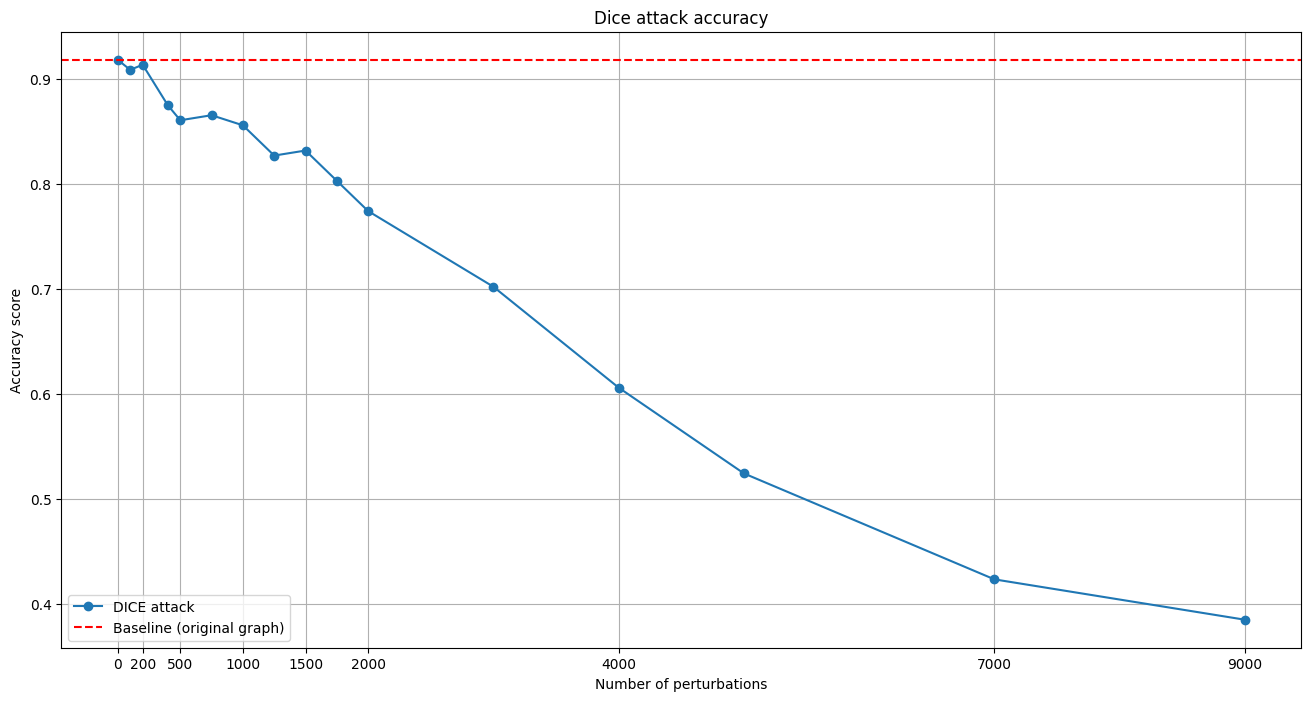

In [302]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

ax.plot(all_perturbations, test_accs_dice, marker='o', label='DICE attack')
ax.axhline(baseline_test_acc, color='red', linestyle='--', label='Baseline (original graph)')
ax.set_xlabel("Number of perturbations")
ax.set_ylabel("Accuracy score")
ax.set_title("Dice attack accuracy")
ax.legend()
ax.grid(True) 
ax.set_xticks(list(all_perturbations[::2]) + [all_perturbations[-1]])
plt.show()

From the plot, we can observe that the accuracy gradually decreases as the number of perturbations increases, which is expected. This happens because the attack removes edges between nodes of the same class, so each node now aggregates less useful information from its neighbors. At the same time, adding edges between nodes of different classes introduces unrelated information and noise, which, when combined with the previous effect, degrades the model’s performance. Hence, even with a relatively small number of perturbations (400, which corresponds to ~7% of the original edges), we already observe a drop of around 4% in accuracy. 

We also observe certain increases in accuracy between consecutive perturbation levels. This can be attributed to the stochasticity in DICE attack, where the selection of edges for removal and insertion is not equally harmful. In particular, if the perturbations target important edges, the performance will inevitably decrease, but if irrelevant or misleading edges are perturbed, the performance may even increase.

In addition, there may be another reason for these increases (i.e., no large decreases), which we analyze through the case of 9000 perturbations. As shown earlier, this configuration removes all edges between nodes of the same class, so one might expect the performance to be close to random (approximately 14%). However, the plot shows that the accuracy actually remains around 38%. This suggests that the previously trained network has learned meaningful information from node features themselves, which can still support classification even when the graph structure is significantly changed. 

#### Open Graph Benchmark

Try applying the techniques you have learned in this class to one of the datasets from the Open Graph Benchmark (OGB).

https://ogb.stanford.edu/docs/home/

$\color{#AA3939}{\text{Q4.2}}$ Choose a task, and design an experimental evaluation based on the metrics recommended by the corresponding OGB evaluator. Report your design choices and how they evolved as you interacted with the dataset. Report performance as it changes with each choice and attempt. Try to motivate why they increased or decreased performance (e.g. increasing depth reduced performance, cleaning/preprocessing the graph increased performance, increasing depth with a different node update increased performance).

Your submission does not have to be competitive with the current leaderboard, but rather show your understanding of the algorithms presented in class and how they interact with real-world scenarios.

$\color{#AA3939}{\text{A4.2}}$ We decided to tackle the task of node classification on `ogbn-arxiv` dataset. This task extends previous work in this assignment, but in a more challenging setting, since we will now operate on larger number of nodes and classes. More specifically, this dataset represents a citation network of arXiv papers, where the goal is to predict one of 40 subject areas for each paper. The data is split into three groups based on publication dates: the training set contains papers published before 2017, the validation set contains papers from 2018, and the test set contains papers published from 2019 onward.

Our experimental evaluation will particularly focus on architectural changes, with the dataset kept fixed throghout all experiments. For evaluation metric, we will keep using accuracy, as suggested by prior work.

In [3]:
!pip install ogb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 2.6 MB/s eta 0:00:00


In [4]:
from ogb.nodeproppred import NodePropPredDataset

arxiv_dataset = NodePropPredDataset(name='ogbn-arxiv') 

Downloaded 0.08 GB: 100%|██████████| 81/81 [00:04<00:00, 16.60it/s]


Extracting dataset/arxiv.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 7958.83it/s]

Saving...


We first implement functions for loading the graph structure and node labels, analogously to the `get_zacharys_karate_club` function. In addition, we implement a separate function to obtain the dataset split masks.

In [10]:
def get_ogbn_arxiv_graph_and_labels(dataset) -> jraph.GraphsTuple:
    """Returns GraphsTuple representing ogbn-arxiv."""
    graph, labels = dataset[0]

    return jraph.GraphsTuple(
        n_node=jnp.array([graph['num_nodes']]),
        n_edge=jnp.array([graph['edge_index'].shape[1]]),
        nodes=jnp.array(graph['node_feat']),
        edges=None,
        globals=None,
        senders=jnp.array(graph['edge_index'][0]),
        receivers=jnp.array(graph['edge_index'][1]),
    ), jnp.asarray(labels).reshape(-1)

def get_ogbn_arxiv_split(dataset):
    """Returns masks for splits."""
    split_idx = dataset.get_idx_split()
    return (jnp.array(split_idx['train']), jnp.array(split_idx['valid']), jnp.array(split_idx['test']))

In [ ]:
ogb_graph, ogb_labels = get_ogbn_arxiv_graph_and_labels(arxiv_dataset)
train_mask, val_mask, test_mask = get_ogbn_arxiv_split(arxiv_dataset)

print(f'Number of nodes: {ogb_graph.n_node[0]}')
print(f'Number of edges: {ogb_graph.n_edge[0]}')
print(f'Node feature shape: {ogb_graph.nodes.shape}')
print(f'Number of classes: {len(jnp.unique(ogb_labels))}')
print(f'Labels shape: {ogb_labels.shape}')
print(f'Train nodes: {len(train_mask)}')
print(f'Val nodes: {len(val_mask)}')
print(f'Test nodes: {len(test_mask)}')

Number of nodes: 169343
Number of edges: 1166243
Node feature shape: (169343, 128)
Number of classes: 40
Labels shape: (169343,)
Train nodes: 90941
Val nodes: 29799
Test nodes: 48603


Next, we implement factory functions `gcn_arxiv_factory` and `gat_arxiv_factory`, which wrap around the existing `gcn_definition` and `gat_definition` functions. The idea here is that, instead of hardcoding the number of layers and their dimensions, the factories accept a `hidden_dims` list, which allows for runtime definition of these layers. However, the role of `hidden_dims` is not the same in the two factory implementations. Specifically, in case of GCN, each element of this list defines one hidden convolution layer and its dimension, after which an additional output layer with 40 dimensions (corresponding to 40 classes) is used. This means that the created GCN network contains `len(hidden_dims)+1` layers in total. In contrast, for GAT, the list also controls the widths of layers, but it creates `len(hidden_dims)` total layers, where first `len(hidden_dims)-1` are true hidden layers, while the last layer is both hidden (via `attention_query_fn=lambda n, d=dim: hk.Linear(d)(n)`) and an output layer (via `node_update_fn=hk.Linear(40)`) Therefore, we must acknowledge that the setup is not equivalent for GCN and GAT. Fortunately, in what follows, we will not compare GCN and GAT layer-wise (e.g., GCN with `[64, 64]` and GAT with `[64, 64]`), but rather analyze each network within its own set of configurations. Overall, this design allows us to easily vary both the depth and width of network architectures and explore performance under different model configurations. 

In [45]:
def gcn_arxiv_factory(hidden_dims: list):
    """Factory for GCN on ogbn-arxiv that allows in-time dimension changes."""
    def gcn_definition_arxiv(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
        """Defines a GCN for the arxiv classification task."""
        for dim in hidden_dims:
            gn = GraphConvolution(
                update_node_fn=lambda n, d=dim: jax.nn.relu(hk.Linear(d)(n)),
                add_self_edges=True)
            graph = gn(graph)
            
        gn = GraphConvolution(update_node_fn=hk.Linear(40)) # output dim is 40 because we have 40 classes
        graph = gn(graph)
        return graph
    return gcn_definition_arxiv

In [ ]:
def gat_arxiv_factory(hidden_dims: list):
    """Factory for GAT on ogbn-arxiv that allows in-time dimension changes."""
    def gat_definition_arxiv(graph: jraph.GraphsTuple) -> jraph.GraphsTuple:
        def _attention_logit_fn(sender_attr: jnp.ndarray, receiver_attr: jnp.ndarray,
                                edges: jnp.ndarray) -> jnp.ndarray:
            del edges
            x = jnp.concatenate((sender_attr, receiver_attr), axis=1)
            return hk.Linear(1)(x)

        for i, dim in enumerate(hidden_dims):
            gn = GAT(
                attention_query_fn=lambda n, d=dim: hk.Linear(d)(n),
                attention_logit_fn=_attention_logit_fn,
                node_update_fn=hk.Linear(40) if i == len(hidden_dims)-1 else None, # only the last layer should be linear in order to output class logits
                add_self_edges=True)
            graph = gn(graph)
        return graph
    return gat_definition_arxiv

We now implement the `optimize_arxiv` function in the same manner as previous `optimize_club` and `optimize_cora` functions. Compared to these implementations, we additionally record the mean execution time per step and the step with the highest validation accuracy. We then return the corresponding training, validation, and test accuracies for this step, and, in the following analysis, report these exact values.

In [ ]:
def optimize_arxiv(network: hk.Transformed, num_steps: int, verbose=True):
    """Solves ogbn-arxiv node classification. Analogous to optimize_cora."""
    params = network.init(jax.random.PRNGKey(42), ogb_graph)

    @jax.jit
    def predict(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, ogb_graph)
      return jnp.argmax(decoded_graph.nodes, axis=1)
    
    @jax.jit
    def prediction_loss(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, ogb_graph)
      # We interpret the decoded nodes as a pair of logits for each node, but
      # we only apply it to labeled nodes.
      log_prob = jax.nn.log_softmax(decoded_graph.nodes[train_mask])
      # The only assignments we know are those in the training set,
      # and since Arxiv is a multi-class network we must one-hot them.
      target = jax.nn.one_hot(ogb_labels[train_mask], 40)
      return -jnp.sum(log_prob * target)
    
    opt_init, opt_update = optax.adam(5e-3)
    opt_state = opt_init(params)

    @jax.jit
    def update(params: hk.Params, opt_state) -> Tuple[hk.Params, Any]:
      """Returns updated params and state."""
      g = jax.grad(prediction_loss)(params)
      updates, opt_state = opt_update(g, opt_state)
      return optax.apply_updates(params, updates), opt_state
    
    @jax.jit
    def accuracy(params: hk.Params) -> jnp.ndarray:
      decoded_graph = network.apply(params, ogb_graph)
      # Compute all three accuracy scores
      train_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[train_mask], axis=1) == ogb_labels[train_mask])
      val_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[val_mask], axis=1) == ogb_labels[val_mask])
      test_acc = jnp.mean(jnp.argmax(decoded_graph.nodes[test_mask], axis=1) == ogb_labels[test_mask])

      return train_acc, val_acc, test_acc

    best_val_acc = 0.0
    best_test_acc = 0.0
    best_train_acc = 0.0
    best_step = 0
    total_time = []

    for step in range(num_steps):
        import time
        t0 = time.time()
        train_acc, val_acc, test_acc = accuracy(params)
        if val_acc > best_val_acc:
            best_train_acc = train_acc
            best_val_acc = val_acc
            best_test_acc = test_acc
            best_step = step
        params, opt_state = update(params, opt_state)
        total_time.append(time.time()-t0)
        if verbose:
            print(f"step {step} train accuracy: {train_acc*100:.2f}%, val accuracy: {val_acc*100:.2f}%, test accuracy: {test_acc*100:.2f}%")

    return predict(params), params, best_train_acc, best_val_acc, best_test_acc, best_step, onp.mean(total_time)

Finally, we design `all_hidden_dims` to systematically explore three axes of network architecture:
1. Depth at fixed width (`[64]`, `[64, 64]`, `[64, 64, 64]`, and similarly for 128 and 256): We aim to test whether adding more layers (increasing depth) improves or degrades performance.
2. Width at fixed depth (`[64]`, `[128]`, `[256]` at depth 1, `[64, 64]`, `[128, 128]`, `[256, 256]` at depth 2, and similarly at depth 3): We fix the depth of layers, and test whether increasing hidden dimensions of layers (increasing width) improves or degrades performance.
3. Combined confiurations (`[128, 64]`, `[256, 128, 128]`, etc.): We study how varying hidden dimensions across layers for a fixed depth affects performance. 

In [ ]:
all_hidden_dims = [
    [64], [64, 64], [64, 64, 64], # depth at fixed width
    [128], [128, 128], [128, 128, 128], # [128, 128] can be compared with [64, 64] for width at fixed depth
    [256], [256, 256], [256, 256, 256],
    [128, 64], [256, 64], [256, 128], # combined
    [256, 128, 64], [256, 128, 128], [256, 256, 128], # combined
]

We will now train and evaluate our GCN and GAT networks across all previously defined configurations.

In [56]:
for hidden_dims in all_hidden_dims:
    network = hk.without_apply_rng(hk.transform(gcn_arxiv_factory(hidden_dims)))
    _, _, best_train, best_val, best_test, best_step, mean_step_time = optimize_arxiv(network, num_steps=100, verbose=False)
    print(f"GCN {hidden_dims} | best step: {best_step} | train acc: {best_train*100:.2f}%, val acc: {best_val*100:.2f}%, test acc: {best_test*100:.2f}% | mean step time: {mean_step_time:.2f}s")

GCN [64] | best step: 97 | train acc: 42.54%, val acc: 37.61%, test acc: 19.06% | mean step time: 0.56s
GCN [64, 64] | best step: 98 | train acc: 42.46%, val acc: 37.30%, test acc: 18.75% | mean step time: 0.78s
GCN [64, 64, 64] | best step: 98 | train acc: 38.82%, val acc: 31.96%, test acc: 15.25% | mean step time: 1.01s
GCN [128] | best step: 99 | train acc: 44.42%, val acc: 38.84%, test acc: 19.50% | mean step time: 0.56s
GCN [128, 128] | best step: 98 | train acc: 44.03%, val acc: 38.75%, test acc: 19.97% | mean step time: 0.80s
GCN [128, 128, 128] | best step: 93 | train acc: 40.76%, val acc: 34.79%, test acc: 16.51% | mean step time: 1.05s
GCN [256] | best step: 99 | train acc: 45.91%, val acc: 40.04%, test acc: 19.85% | mean step time: 0.58s
GCN [256, 256] | best step: 98 | train acc: 45.52%, val acc: 39.79%, test acc: 20.18% | mean step time: 0.87s
GCN [256, 256, 256] | best step: 98 | train acc: 42.84%, val acc: 35.66%, test acc: 16.89% | mean step time: 1.15s
GCN [128, 64] | 

In [57]:
for hidden_dims in all_hidden_dims:
    network = hk.without_apply_rng(hk.transform(gat_arxiv_factory(hidden_dims)))
    _, _, best_train, best_val, best_test, best_step, mean_step_time = optimize_arxiv(network, num_steps=100, verbose=False)
    print(f"GAT {hidden_dims} | best step: {best_step} | train acc: {best_train*100:.2f}%, val acc: {best_val*100:.2f}%, test acc: {best_test*100:.2f}% | mean step time: {mean_step_time:.2f}s")

GAT [64] | best step: 99 | train acc: 56.30%, val acc: 55.99%, test acc: 51.12% | mean step time: 0.15s
GAT [64, 64] | best step: 99 | train acc: 58.58%, val acc: 57.61%, test acc: 51.46% | mean step time: 0.19s
GAT [64, 64, 64] | best step: 98 | train acc: 57.46%, val acc: 56.05%, test acc: 50.65% | mean step time: 0.23s
GAT [128] | best step: 99 | train acc: 58.79%, val acc: 58.09%, test acc: 52.77% | mean step time: 0.17s
GAT [128, 128] | best step: 98 | train acc: 60.42%, val acc: 58.71%, test acc: 52.32% | mean step time: 0.24s
GAT [128, 128, 128] | best step: 92 | train acc: 59.66%, val acc: 58.20%, test acc: 52.84% | mean step time: 0.30s
GAT [256] | best step: 99 | train acc: 60.39%, val acc: 59.12%, test acc: 53.58% | mean step time: 0.22s
GAT [256, 256] | best step: 99 | train acc: 62.37%, val acc: 59.90%, test acc: 53.41% | mean step time: 0.35s
GAT [256, 256, 256] | best step: 97 | train acc: 61.26%, val acc: 59.11%, test acc: 52.92% | mean step time: 0.46s
GAT [128, 64] | 

For better comparison and analysis, we will collect and report previous results in two tables below. To clarify, the *Hidden Dimensions* column corresponds to the values provided in the `hidden_dims` parameter. For GCN, this column shows dimensions of its hidden layers, with 40-dimensional output layer left out. For GAT, the last dimension in each row corresponds to the final layer, which first projects to that dimension and then outputs 40 class logits.

| Network | Hidden Dimensions | Best Step | Train Acc | Val Acc | Test Acc | Mean Step Time |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| GCN | 64 | 97 | 42.54% | 37.61% | 19.06% | 0.56s |
| GCN | 64 &rarr; 64 | 98 | 42.46% | 37.30% | 18.75% | 0.78s |
| GCN | 64 &rarr; 64 &rarr; 64 | 98 | 38.82% | 31.96% | 15.25% | 1.01s |
| GCN | 128 | 99 | 44.42% | 38.84% | 19.50% | 0.56s |
| GCN | 128 &rarr; 128 | 98 | 44.03% | 38.75% | 19.97% | 0.80s |
| GCN | 128 &rarr; 128 &rarr; 128 | 93 | 40.76% | 34.79% | 16.51% | 1.05s |
| GCN | 256 | 99 | 45.91% | 40.04% | 19.85% | 0.58s |
| GCN | 256 &rarr; 256 | 98 | 45.52% | 39.79% | **20.18%** | 0.87s |
| GCN | 256 &rarr; 256 &rarr; 256 | 98 | 42.84% | 35.66% | 16.89% | 1.15s |
| GCN | 128 &rarr; 64 | 98 | 43.66% | 38.42% | 19.62% | 0.81s |
| GCN | 256 &rarr; 64 | 97 | 43.99% | 38.82% | 19.88% | 0.84s |
| GCN | 256 &rarr; 128 | 99 | 44.85% | 39.24% | 19.89% | 0.86s |
| GCN | 256 &rarr; 128 &rarr; 64 | 91 | 41.81% | 35.64% | 17.03% | 1.10s |
| GCN | 256 &rarr; 128 &rarr; 128 | 98 | 42.39% | 34.90% | 16.42% | 1.11s |
| GCN | 256 &rarr; 256 &rarr; 128 | 81 | 41.32% | 35.88% | 17.33% | 1.16s |

| Network | Hidden Dimensions | Best Step | Train Acc | Val Acc | Test Acc | Mean Step Time |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| GAT | 64 | 99 | 56.30% | 55.99% | 51.12% | 0.15s |
| GAT | 64 &rarr; 64 | 99 | 58.58% | 57.61% | 51.46% | 0.19s |
| GAT | 64 &rarr; 64 &rarr; 64 | 98 | 57.46% | 56.05% | 50.65% | 0.23s |
| GAT | 128 | 99 | 58.79% | 58.09% | 52.77% | 0.17s |
| GAT | 128 &rarr; 128 | 98 | 60.42% | 58.71% | 52.32% | 0.24s |
| GAT | 128 &rarr; 128 &rarr; 128 | 92 | 59.66% | 58.20% | 52.84% | 0.30s |
| GAT | 256 | 99 | 60.39% | 59.12% | **53.58%** | 0.22s |
| GAT | 256 &rarr; 256 | 99 | 62.37% | 59.90% | 53.41% | 0.35s |
| GAT | 256 &rarr; 256 &rarr; 256 | 97 | 61.26% | 59.11% | 52.92% | 0.46s |
| GAT | 128 &rarr; 64 | 98 | 59.79% | 58.45% | 52.18% | 0.22s |
| GAT | 256 &rarr; 64 | 98 | 61.14% | 59.41% | 53.06% | 0.27s |
| GAT | 256 &rarr; 128 | 97 | 61.69% | 59.61% | 53.22% | 0.29s |
| GAT | 256 &rarr; 128 &rarr; 64 | 95 | 59.99% | 58.14% | 51.87% | 0.34s |
| GAT | 256 &rarr; 128 &rarr; 128 | 97 | 60.70% | 58.60% | 52.87% | 0.36s |
| GAT | 256 &rarr; 256 &rarr; 128 | 99 | 61.15% | 58.92% | 53.31% | 0.41s |

Our best test accuracy across all configurations is 53.58%, and is achieved using GAT network with a single, 256-dimensional hidden (and output) layer. In contrast, the best GCN performance is 20.18%, and is achieved with two 256-dimensional hidden layers. Overall, GAT outperforms GCN by ~33%+ across all configurations, which proves the impact of the attention mechanism.

We will now move to ablation across the three previously mentioned axis. We begin with depth at fixed width, where we fix the hidden dimension, vary the number of layers and analyze the change in performance. We first focus on 64-width GCN configurations (i.e., [64], [64 &rarr; 64], and [64 &rarr; 64 &rarr; 64]) and observe that, as the number of layer grows, the test accuracy decreases continuosly as 19.06% &rarr; 18.75% &rarr; 15.25%. In the case of 128-width networks, we observe change in test accuracy as 19.50% &rarr; 19.97% &rarr; 16.51%, and for 256-width, we have 19.85% &rarr; 20.18% &rarr; 16.89%. Thus, increasing depth from 1 to 2 layers in the last two setups results in minimal accuracy improvement, while adding the 3rd layer leads to a large drop. This behavior can be explained through oversmoothing phenomenom, where increasing network depth leads to homogeneous and indistinguishable node representations, which ultimately results in worse performance. For GAT, the degradation in performance is noticeably weaker (e.g., for 256-width configuration, test accuracy changes as 53.58% &rarr; 53.41% &rarr; 52.92%), which suggests that attention layers can mitigate this effect by reducing the importance of unrelated and uninformative neighbors. Overall, we can conclude that increasing the depth does not improve performance.

Next, we analyze width at fixed depth, where we fix the number of layers, and vary their dimension.  We can first observe that, for a single layer configurations, the accuracy for both GCN and GAT increases as the width grows from 64 to 128 to 256: 19.06% &rarr; 19.50% &rarr; 19.85% for GCN, and 51.12% &rarr; 52.77% &rarr; 53.58% for GAT. The same pattern is observed for deeper networks as well. For 2-layer GCN, the accuracy changes as 18.75% &rarr; 19.97% &rarr; 20.18%, and for 3-layer GCN it increases as 15.25% &rarr; 16.51% &rarr; 16.89%. Similarly, for GAT, the accuracy changes as 51.46% &rarr; 52.32% &rarr; 53.41% for 2-layer configurations, and as 50.65% &rarr; 52.84% &rarr; 52.92% for 3-layer ones. This behavior was expected, as having higher dimensions in layers allow the network to capture richer graph representations. Overall, we can conclude that increasing the width of the network improves performance.

In the last experiment, we test several combined configurations, or, more specifically, explore how equal-width layers (e.g., [256 &rarr;  256]) compare to layers of the same depth, but with different unique values (e.g., [256 &rarr; 128]), in terms of performance. First, for 2-layer GCN configurations, 256 &rarr; 256 network (with accuracy of 20.18%) outperforms its counterparts 256 &rarr; 128 (acc. 19.89%) and 256 &rarr; 64 (acc. 19.88%), and the same holds for 128 &rarr; 128 configuration (acc. 19.97%) when compared to 128 &rarr; 64 (acc. 19.62%). The same pattern is observed in GAT configurations as well. Overall, these results are consistent with our previous observation that higher width improves performance. However, when looking at 3-layer networks, the outcome is different. In the case of GAT, although 256 &rarr; 256 &rarr; 256 configuration (acc. 52.92%) outperforms 256 &rarr; 128 &rarr; 64 (acc. 51.87%) and 256 &rarr; 128 &rarr; 128 (acc. 52.87%), it achieves lower performance than 256 &rarr; 256 &rarr; 128 configuration (acc. 53.31%). Again, we observe the same pattern in the corresponding GCN configurations. We can relate this to the observations from the first experiment, where adding a 3rd layer consistently decreased performance compared to 1-layer and 2-layer configurations. However, as we have seen now, this drop can be mitigated if the third layer has a smaller width. Still, compared to lower-depth configurations, these results remain worse overall.

# Summary
In this tutorial, we learned about how to represent directed and undirected graphs in jraph, how to create the basic GNN blocks (GCN + GAT) and how to compose them into GNNs. We also learned about three types of graph predictions tasks (node classification, link prediction and graph classification) and trained a model on each of these tasks.


To practice your knowledge, you can:
* Create your own graphs, e.g. following the toy graph template and adding nodes, edges, features.
* Modify the GNN blocks, e.g. by changing the `update_node_fn()` / `update_edge_fn()` functions.
* Train a model on a different dataset and/or task.